# **Anomaly detection**

In [ ]:
import datetime
import importlib
import itertools
import math
import os
import random
import warnings
import matplotlib.pyplot as plt
import neuralforecast.auto as na
import neuralforecast.models as m
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import eda
import training
import visuals
from copy import deepcopy
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import DistributionLoss, MAE
from optuna.samplers import TPESampler
from pyod.models.auto_encoder import AutoEncoder
from ray import tune
from ray.tune.search.optuna import OptunaSearch
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    mean_absolute_error,
    recall_score,
    root_mean_squared_error,
)
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, PowerTransformer, StandardScaler
from sklearn.svm import SVC
from sktime.forecasting.fbprophet import Prophet
from sktime.split import SlidingWindowSplitter
from statsforecast import StatsForecast
from statsforecast.models import HistoricAverage, Naive, RandomWalkWithDrift
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, het_white
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf
from utilsforecast.plotting import plot_series

importlib.reload(eda)
importlib.reload(training)
importlib.reload(visuals)

warnings.filterwarnings("ignore")
%matplotlib inline

In [ ]:
import logging
logger = logging.getLogger('cmdstanpy')
logger.addHandler(logging.NullHandler())
logger.propagate = False
logger.setLevel(logging.CRITICAL)


# Pytorch
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)

# Ray
logging.getLogger("ray").setLevel(logging.ERROR)

# Optuna
optuna.logging.set_verbosity(optuna.logging.ERROR)

In [ ]:
path = os.getcwd()

# **1. Loading and exploration of the dataset**

##### **Dataset description**

Dataset contains following features:


*	datetime - Represents dates and times of the moment when the value is written to the database (YYYY-MM-DD hh:mm:ss)

*	Accelerometer1RMS - Shows a vibration acceleration (Amount of g units)

*	Accelerometer2RMS - Shows a vibration acceleration (Amount of g units)

*	Current - Shows the amperage on the electric motor (Ampere)

*	Pressure - Represents the pressure in the loop after the water pump (Bar)

*	Temperature - Shows the temperature of the engine body (The degree Celsius)

*	Thermocouple - Represents the temperature of the fluid in the circulation loop (The degree Celsius)

*	Voltage - Shows the voltage on the electric motor (Volt)

*	RateRMS - Represents the circulation flow rate of the fluid inside the loop (Liter per minute)

*	anomaly - Shows if the point is anomalous (0 or 1)

*	changepoint - Shows if the point is a changepoint for collective anomalies (0 or 1)


In [ ]:
skab = pd.read_csv('alldata_skab.csv')

In [ ]:
skab.head(10)

,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
0,2020-02-08 13:30:47,0.206030,0.277924,1.81019,0.382638,90.1740,26.7760,228.208,121.664,NaN,NaN
1,2020-02-08 13:30:48,0.204366,0.275727,2.66317,-0.273216,90.2836,26.7760,227.245,122.000,NaN,NaN
2,2020-02-08 13:30:49,0.206103,0.278526,2.63758,0.382638,89.8666,26.7821,237.872,122.000,NaN,NaN
3,2020-02-08 13:30:51,0.204775,0.276948,2.32851,0.382638,90.2192,26.7773,230.422,121.338,NaN,NaN
4,2020-02-08 13:30:52,0.206052,0.278141,2.53422,0.382638,90.1449,26.7773,219.454,121.664,NaN,NaN
5,2020-02-08 13:30:53,0.204336,0.278100,2.56922,0.054711,90.2703,26.7658,221.089,122.000,NaN,NaN
6,2020-02-08 13:30:54,0.205697,0.278892,1.95859,0.054711,90.2250,26.7750,232.327,122.000,NaN,NaN
7,2020-02-08 13:30:55,0.204775,0.277663,2.49374,0.054711,90.0302,26.7827,231.269,122.000,NaN,NaN
8,2020-02-08 13:30:56,0.206435,0.277730,1.87371,0.054711,89.9812,26.7870,228.727,121.338,NaN,NaN
9,2020-02-08 13:30:57,0.202500,0.278587,2.58620,0.382638,90.1731,26.7865,229.672,121.664,NaN,NaN


In [ ]:
skab['datetime'] = pd.to_datetime(skab['datetime'], format = '%Y-%m-%d %H:%M:%S')

In [ ]:
skab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46623 entries, 0 to 46622
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   datetime             46623 non-null  datetime64[ns]
 1   Accelerometer1RMS    46623 non-null  float64       
 2   Accelerometer2RMS    46623 non-null  float64       
 3   Current              46623 non-null  float64       
 4   Pressure             46623 non-null  float64       
 5   Temperature          46623 non-null  float64       
 6   Thermocouple         46623 non-null  float64       
 7   Voltage              46623 non-null  float64       
 8   Volume Flow RateRMS  46623 non-null  float64       
 9   anomaly              37222 non-null  float64       
 10  changepoint          37222 non-null  float64       
dtypes: datetime64[ns](1), float64(10)
memory usage: 3.9 MB


In [ ]:
skab.anomaly = skab.anomaly.astype(object)
skab.changepoint = skab.changepoint.astype(object)


In [ ]:
skab.iloc[:,1:].describe(include='all')

,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
count,46623.000000,46623.000000,46623.000000,46623.000000,46623.000000,46623.000000,46623.000000,46623.000000,37222.0,37222.0
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,2.0
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24055.0,37093.0
mean,0.129438,0.163012,1.656340,0.080327,79.330014,26.565384,229.578540,75.645930,NaN,NaN
std,0.126072,0.144206,0.794592,0.259528,9.416707,2.538214,10.946809,45.642435,NaN,NaN
min,0.025553,0.036098,0.355411,-1.257000,65.089000,22.020900,200.744000,0.555512,NaN,NaN
25%,0.027434,0.040402,0.980753,0.054711,69.498050,24.648150,223.561000,32.000000,NaN,NaN
50%,0.080350,0.130013,1.369790,0.054711,84.935700,25.596700,229.861000,73.020200,NaN,NaN
75%,0.215624,0.268642,2.479320,0.382638,88.627350,29.148150,235.936500,126.000000,NaN,NaN


In [ ]:
skab.datetime.dt.date.unique()

array([datetime.date(2020, 2, 8), datetime.date(2020, 3, 1),
       datetime.date(2020, 3, 9)], dtype=object)

In [ ]:
ranges = {}
for i, day in enumerate(skab.datetime.dt.date.unique()):
    ranges[i] = pd.date_range(start = skab.loc[skab.datetime.dt.date==day,'datetime'][:1].values[0],end = skab.loc[skab.datetime.dt.date==day,'datetime'][-1:].values[0], freq = 's')
    print(f'Day: {day}\nRange: {ranges[i][0]} - {ranges[i][-1]}\nMissing dates: {1-len(skab.loc[skab.datetime.dt.date==day,"datetime"])/len(ranges[i])}\nNaNs:\n{skab.loc[skab.datetime.dt.date==day,:].isna().sum()/len(skab.loc[skab.datetime.dt.date==day,:])}')
    print(f'NaN range:\n{skab.loc[(skab.datetime.dt.date==day)&(skab.anomaly.isna()),"datetime"]}')

Day: 2020-02-08
Range: 2020-02-08 13:30:47 - 2020-02-08 19:34:45
Missing dates: 0.05462704336279134
NaNs:
datetime               0.000000
Accelerometer1RMS      0.000000
Accelerometer2RMS      0.000000
Current                0.000000
Pressure               0.000000
Temperature            0.000000
Thermocouple           0.000000
Voltage                0.000000
Volume Flow RateRMS    0.000000
anomaly                0.455342
changepoint            0.455342
dtype: float64
NaN range:
0      2020-02-08 13:30:47
1      2020-02-08 13:30:48
2      2020-02-08 13:30:49
3      2020-02-08 13:30:51
4      2020-02-08 13:30:52
               ...        
9962   2020-02-08 16:16:43
9965   2020-02-08 16:16:44
9967   2020-02-08 16:16:45
9969   2020-02-08 16:16:46
9970   2020-02-08 16:16:47
Name: datetime, Length: 9401, dtype: datetime64[ns]
Day: 2020-03-01
Range: 2020-03-01 15:44:06 - 2020-03-01 17:20:49
Missing dates: 0.396106133700896
NaNs:
datetime               0.0
Accelerometer1RMS      0.0
Accelerom

##### Check for NaNs

In [ ]:
n = skab.loc[skab.anomaly.isna(),['datetime']]
min_na, sec_na = eda.show_time(n)

Hour/minute:
13: [30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]
Hour/minute:
14: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]
Hour/minute:
15: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]
Hour/minute:
16: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Hour/#seconds:
13:             [12, 56, 56, 56, 57, 56, 57, 56, 56, 56, 57, 56, 56, 56, 56, 57, 56, 57, 56, 56, 56, 57, 56, 54, 53, 57, 56, 57, 56, 56]
Hour/#seconds:
14:             [57, 56, 56, 56, 56, 56, 57, 56, 57, 56, 57, 56, 56, 56, 56, 55, 57, 55, 56, 56, 56, 56, 56, 56, 56, 55, 56

NaNs are present at the beginning of the dataset, only for the first 4 hours of 8/2/2020. Those rows will be dropped.

In [ ]:
skab1 = skab.dropna()
for i, day in enumerate(skab1.datetime.dt.date.unique()):
    print(f'{day}:{skab1.loc[skab1.datetime.dt.date==day,"datetime"].dt.hour.unique()}')

2020-02-08:[16 17 18 19]
2020-03-01:[15 16 17]
2020-03-09:[10 11 12 13 14 15 16 17]


In [ ]:
values_per_day = {}
for day in skab1.datetime.dt.date.unique():
    print(f'{day}:\n')
    values_per_day[day] = [eda.show_time(skab1.loc[skab1.datetime.dt.date==day,['datetime']])]

2020-02-08:

Hour/minute:
16: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]
Hour/minute:
17: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]
Hour/minute:
18: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]
Hour/minute:
19: [0, 1, 2, 3, 4, 5, 6, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
Hour/#seconds:
16:             [11, 57, 57, 57, 57, 57, 57, 58, 57, 57, 57, 58, 57, 57, 58, 57, 57, 58, 57, 57, 55, 48, 58, 57, 58, 57, 57, 58, 57, 57, 58

Dataset contains many missing timesteps, but also duplicated ones.

##### Handling duplicates

In [ ]:
# Removing duplicated rows
skab2 = skab1.drop_duplicates()

len(skab2)

37082

In [ ]:
# Checking for more duplicates

In [ ]:
skab2.datetime.duplicated().sum()

221

In [ ]:
d1 = skab2[skab2.datetime.duplicated()]['datetime']

In [ ]:
duplicates = skab2[skab2.datetime.isin(d1)]
duplicates

,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
18318,2020-02-08 18:47:29,0.243698,0.293689,2.82553,0.382638,85.5950,29.4542,222.570,125.69100,0.0,0.0
18319,2020-02-08 18:47:29,0.243698,0.293689,2.82553,0.382638,85.5950,29.4542,222.570,125.69100,1.0,0.0
18320,2020-02-08 18:47:30,0.243417,0.288178,2.92453,0.054711,85.5621,29.4521,233.630,125.31100,0.0,0.0
18321,2020-02-08 18:47:30,0.243417,0.288178,2.92453,0.054711,85.5621,29.4521,233.630,125.31100,1.0,0.0
18322,2020-02-08 18:47:31,0.241315,0.289644,3.03341,0.054711,85.3922,29.4462,244.891,125.00000,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
18755,2020-02-08 18:51:50,0.260644,0.300924,2.16641,0.054711,85.4640,29.3704,227.270,8.94094,0.0,0.0
18756,2020-02-08 18:51:51,0.262957,0.307295,2.45724,0.054711,85.3587,29.3704,220.369,0.55639,1.0,0.0
18757,2020-02-08 18:51:51,0.262957,0.307295,2.45724,0.054711,85.3587,29.3704,220.369,0.55639,0.0,0.0
18758,2020-02-08 18:51:55,0.254588,0.294479,2.37001,-0.273216,85.4954,29.3783,225.190,16.61840,0.0,1.0


In [ ]:
skab2.iloc[:,:-2].duplicated().sum()

221

Some rows have two different values in either 'anomaly' or 'changepoint' columns, and the rest of columns is duplicated

In [ ]:
# Putting NaNs where anomaly is duplicated but changepoint has 2 different values
skab2.loc[skab2['datetime'].isin(duplicates[duplicates.iloc[:,:-1].duplicated()]['datetime']),'changepoint'] = np.NaN
skab2 = skab2.drop_duplicates()

In [ ]:
# Putting NaNs where changepoint is duplicated but  anomaly has 2 different values
skab2.loc[skab2['datetime'].isin(
    duplicates[duplicates.loc[:,~duplicates.columns.isin(['anomaly'])].duplicated()]['datetime']),'anomaly'] = np.NaN
skab3 = skab2.drop_duplicates()

In [ ]:
len(skab3) - len(skab3.datetime.unique())

1

In [ ]:
skab3.loc[skab3.datetime.isin(skab3[skab3.datetime.duplicated()].datetime),:]

,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
18738,2020-02-08 18:51:37,0.263712,0.301634,2.58853,-0.273216,85.862,29.3451,216.019,16.1353,0.0,0.0
18739,2020-02-08 18:51:37,0.263712,0.301634,2.58853,-0.273216,85.862,29.3451,216.019,16.1353,1.0,1.0


In [ ]:
# Putting NaNs where both changepoint and anomaly have 2 different values
skab3.loc[skab3.datetime.isin(skab3[skab3.datetime.duplicated()].datetime),'anomaly'] = np.NaN
skab3.loc[skab3.datetime.isin(skab3[skab3.datetime.duplicated()].datetime),'changepoint'] = np.NaN
skab3 = skab3.drop_duplicates()

In [ ]:
len(skab3) - len(skab3.datetime.unique())

0

##### Visualizations

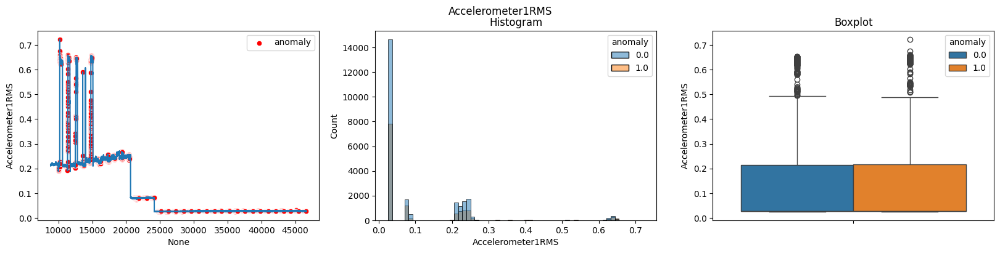

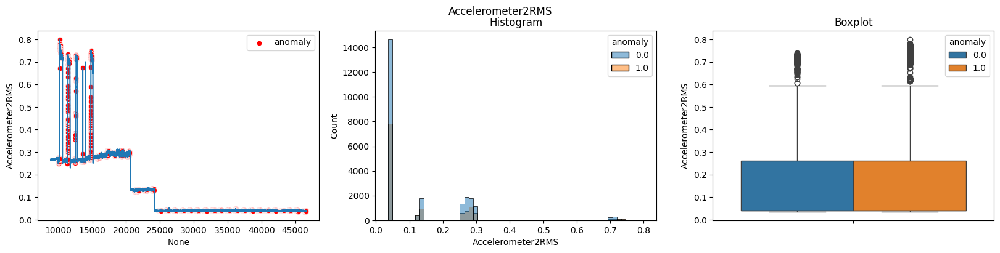

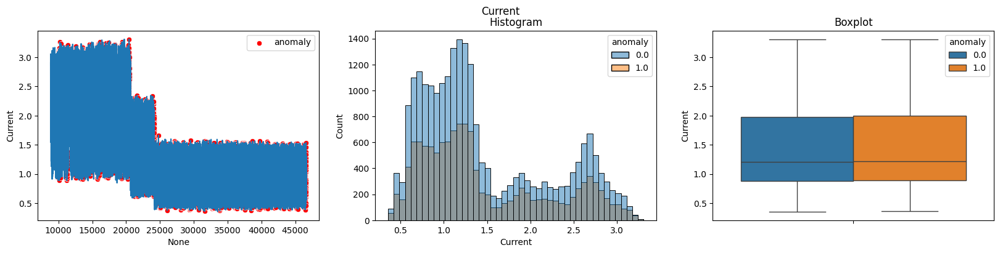

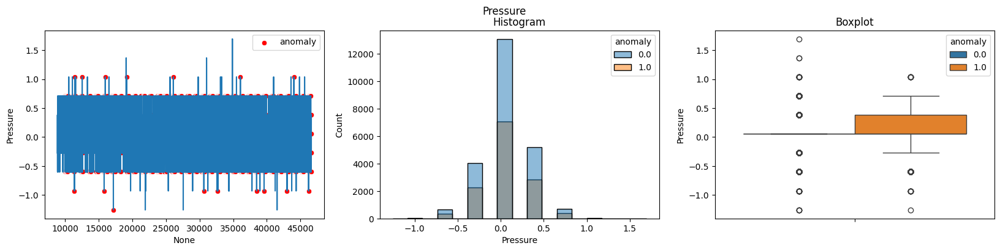

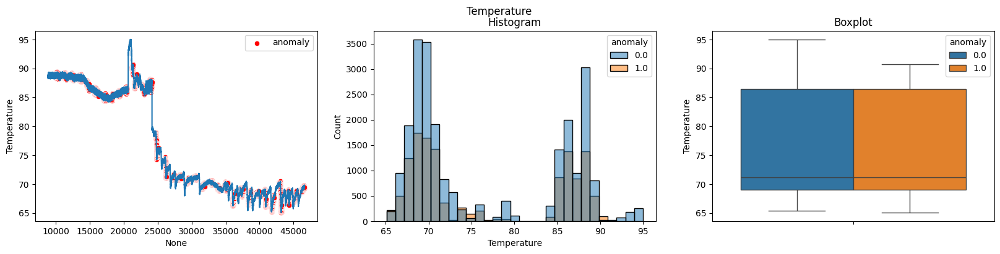

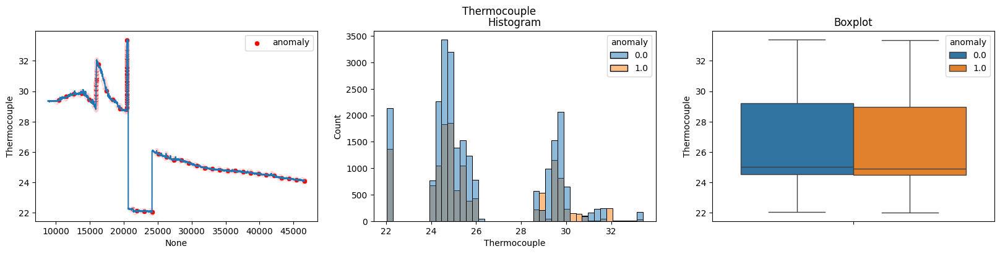

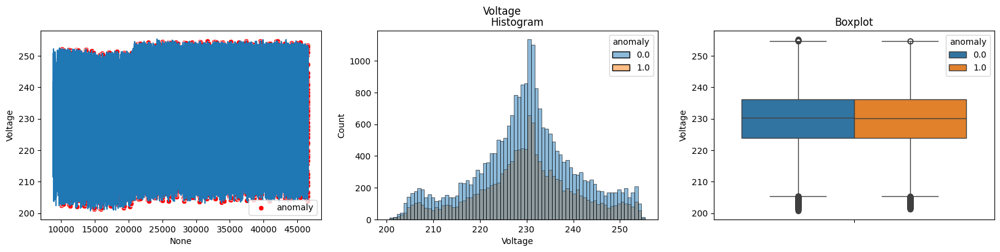

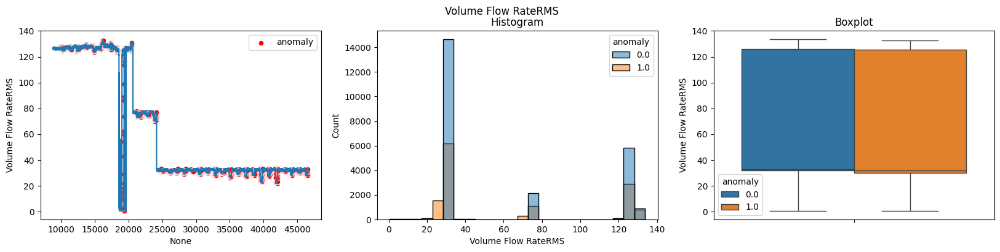

In [ ]:
# Data exploration
eda.multiplot(skab3)

In [ ]:
# Seasonality check
day_hour = skab3.groupby([skab3.datetime.dt.date, skab3.datetime.dt.hour]).count().index

2020-02-08 16


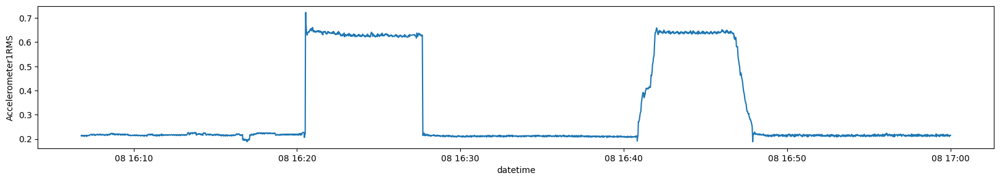

2020-02-08 16


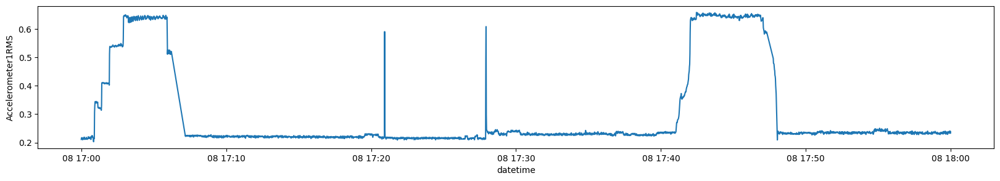

2020-02-08 16


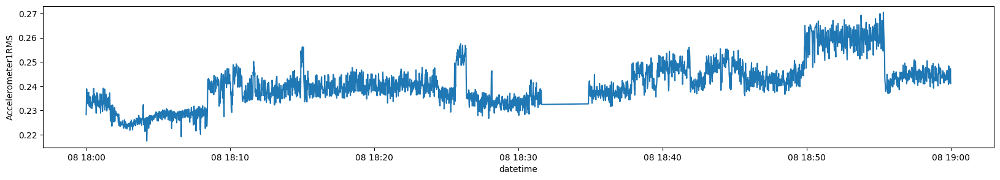

2020-02-08 16


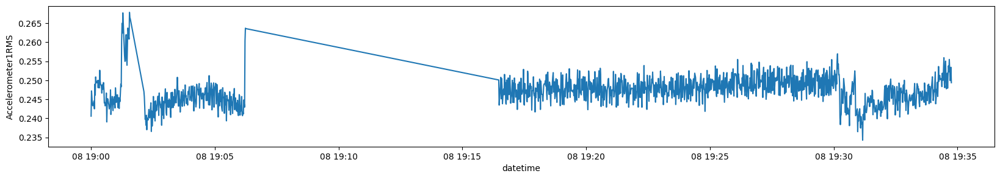

2020-02-08 16


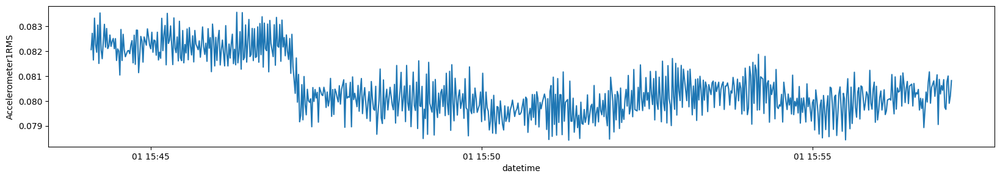

2020-02-08 16


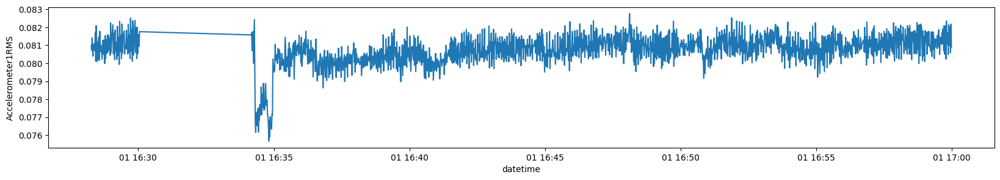

2020-02-08 16


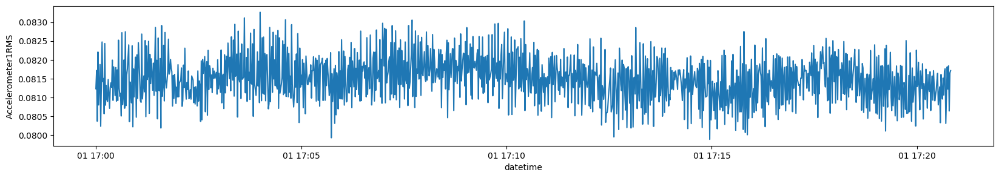

2020-02-08 16


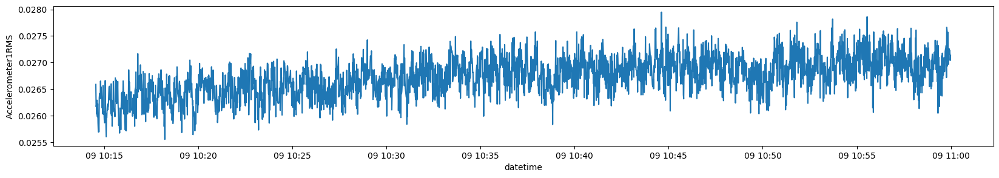

2020-02-08 16


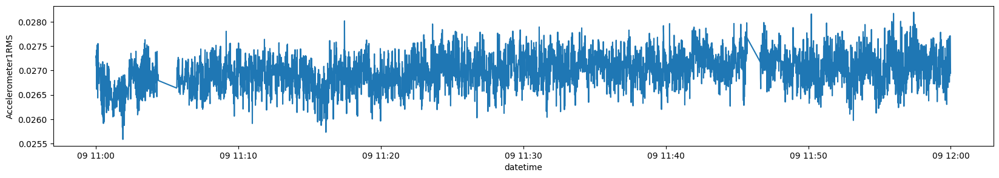

2020-02-08 16


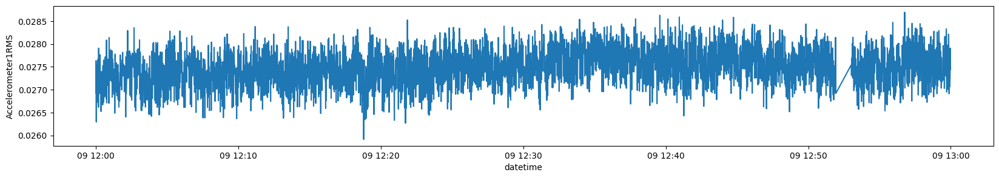

2020-02-08 16


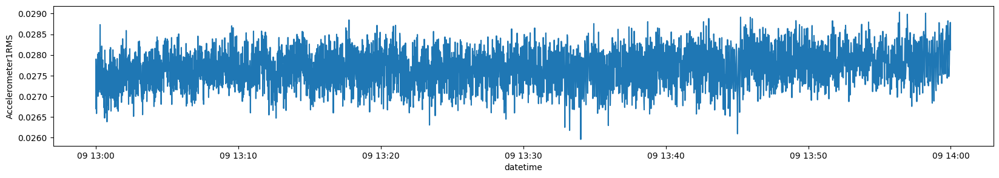

2020-02-08 16


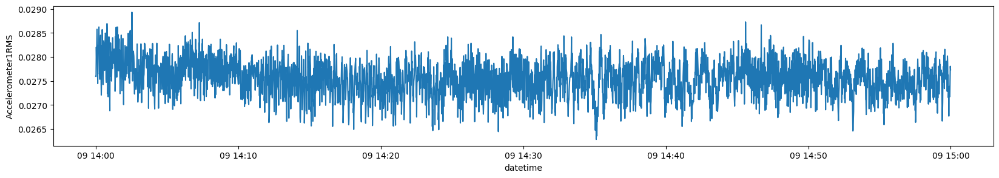

2020-02-08 16


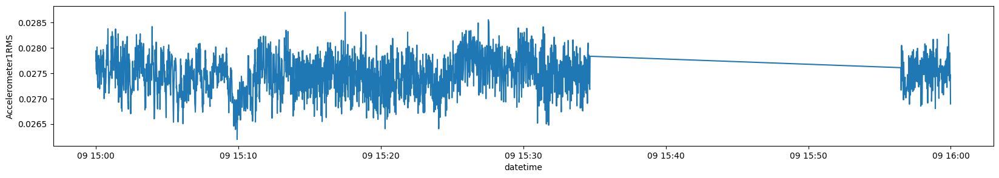

2020-02-08 16


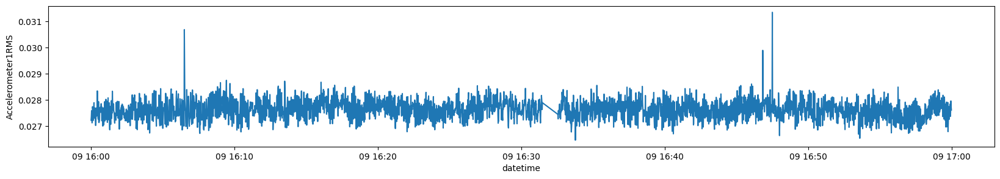

2020-02-08 16


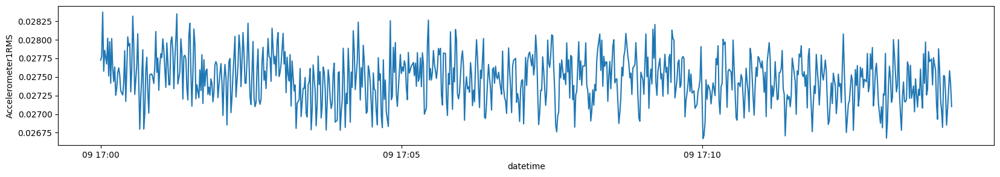

2020-02-08 16


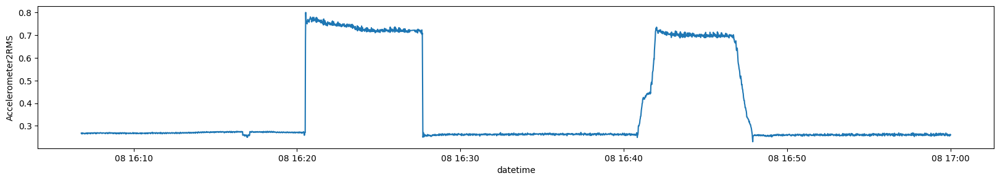

2020-02-08 16


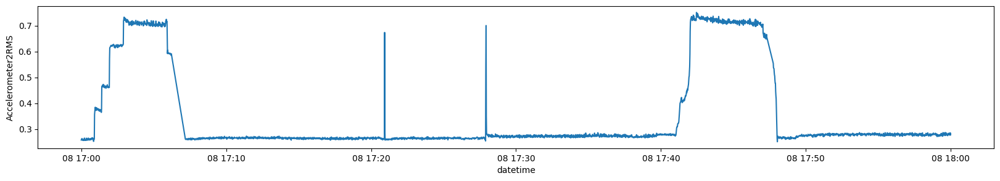

2020-02-08 16


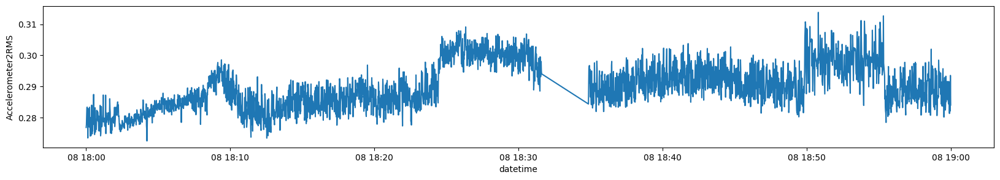

2020-02-08 16


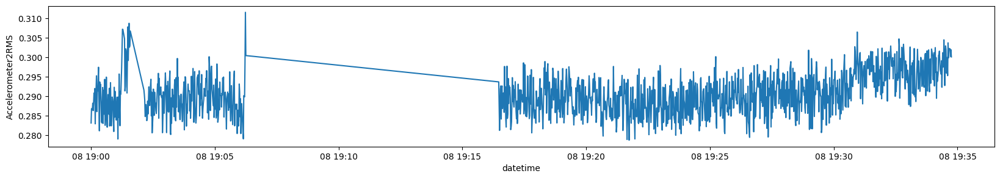

2020-02-08 16


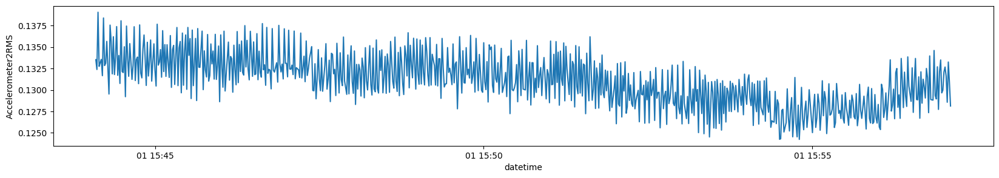

2020-02-08 16


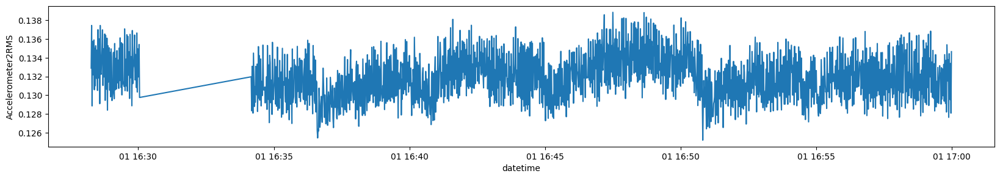

2020-02-08 16


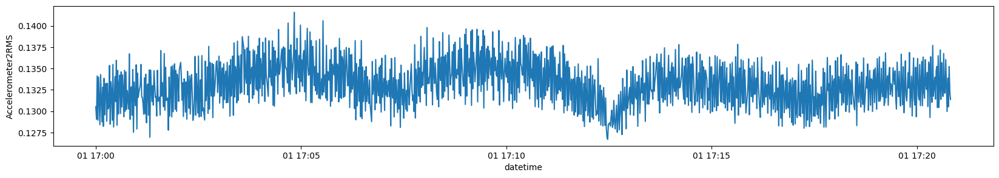

2020-02-08 16


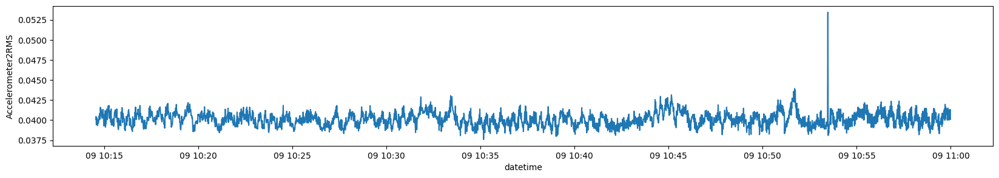

2020-02-08 16


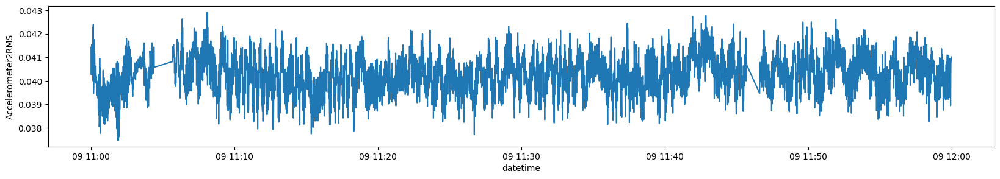

2020-02-08 16


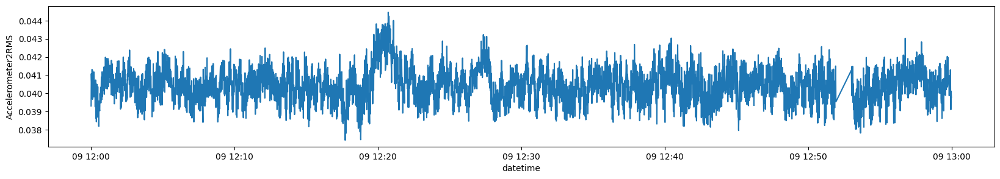

2020-02-08 16


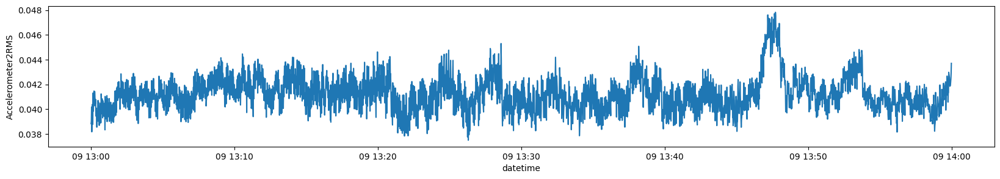

2020-02-08 16


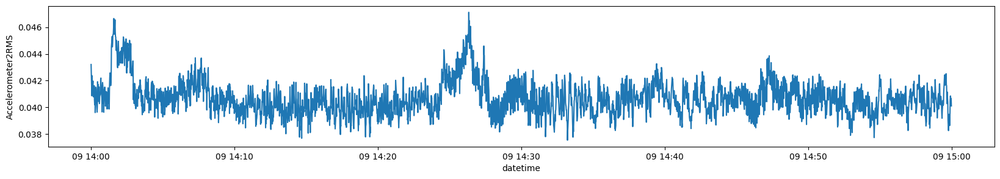

2020-02-08 16


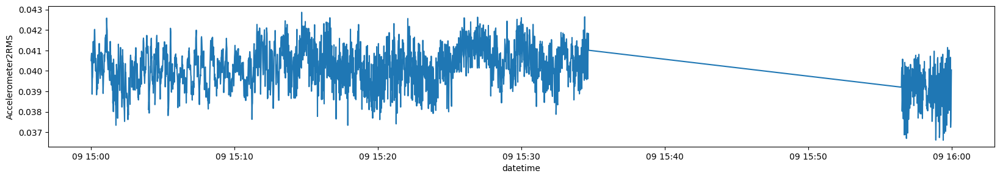

2020-02-08 16


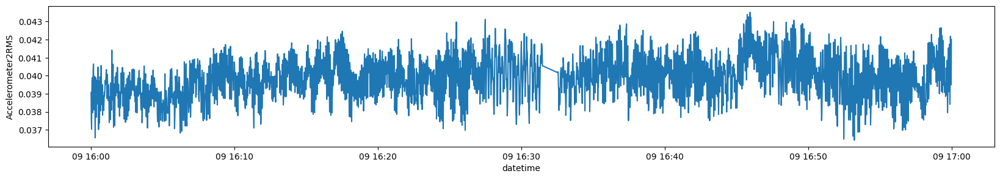

2020-02-08 16


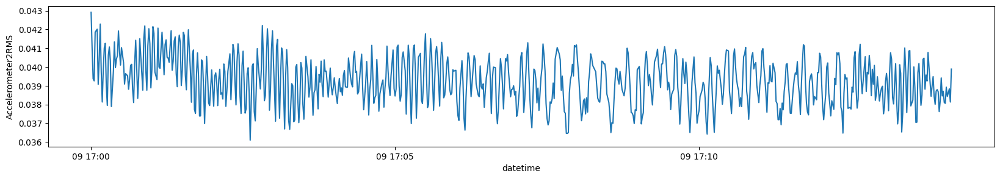

2020-02-08 16


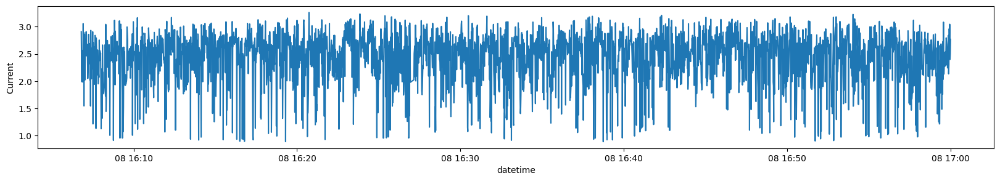

2020-02-08 16


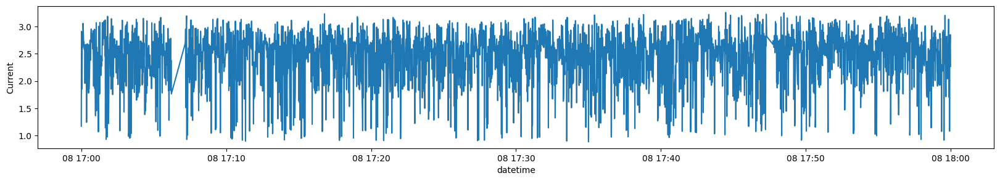

2020-02-08 16


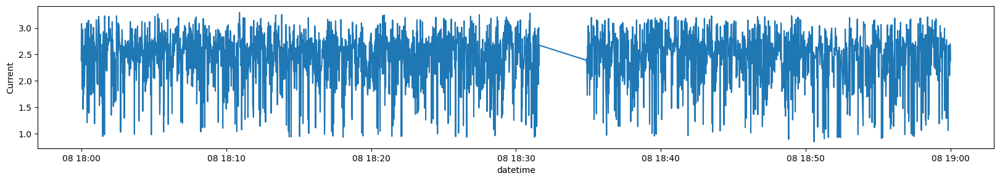

2020-02-08 16


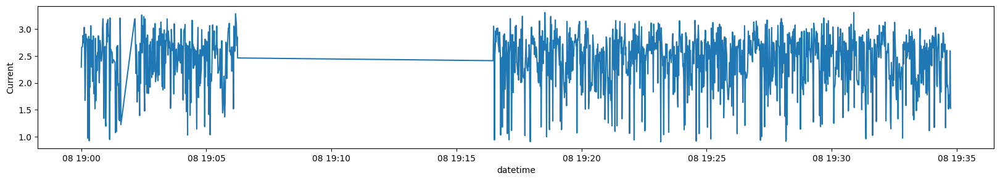

2020-02-08 16


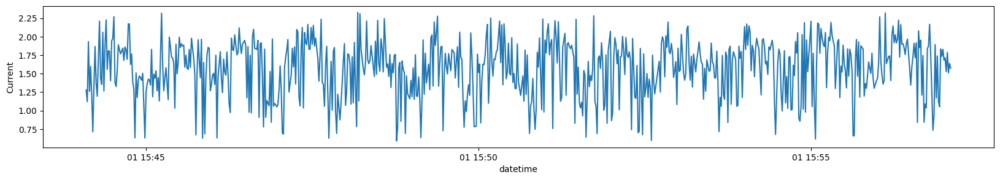

2020-02-08 16


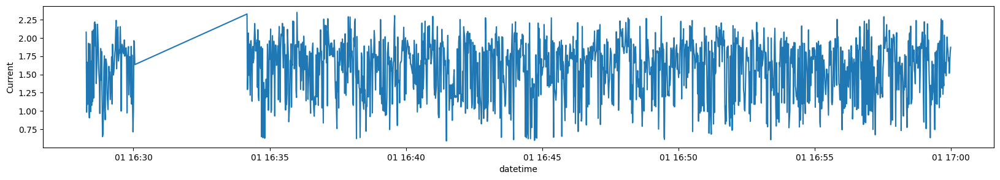

2020-02-08 16


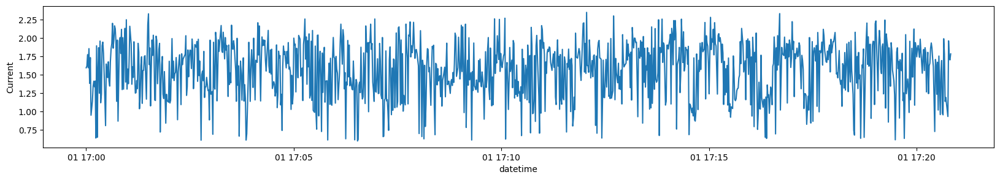

2020-02-08 16


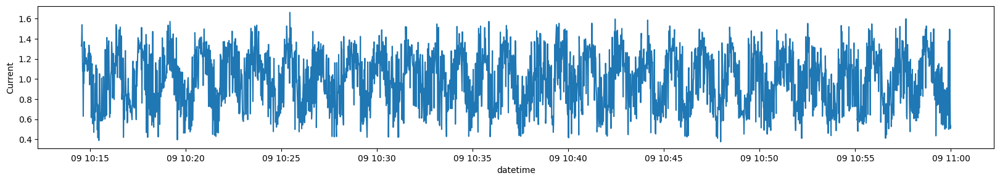

2020-02-08 16


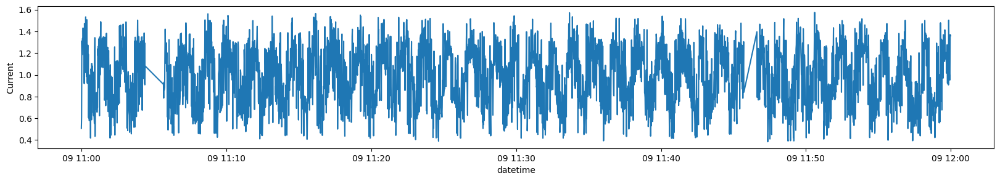

2020-02-08 16


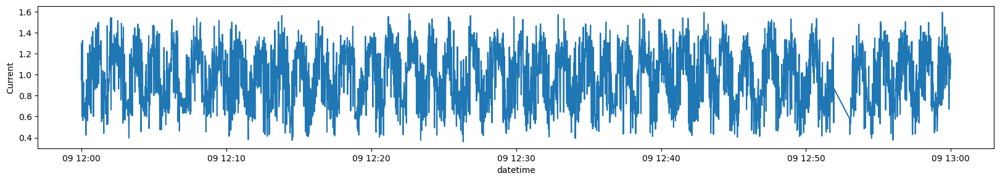

2020-02-08 16


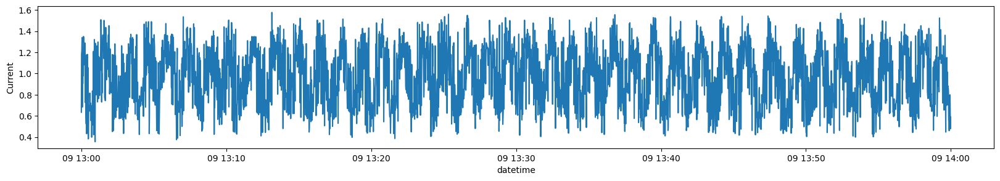

2020-02-08 16


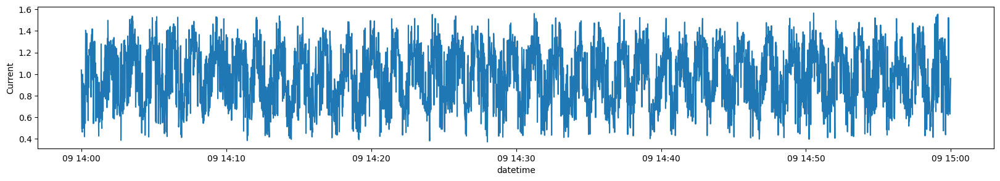

2020-02-08 16


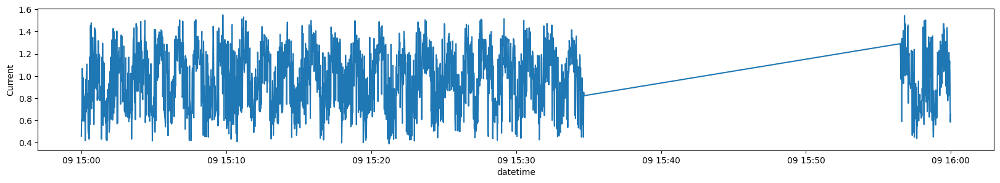

2020-02-08 16


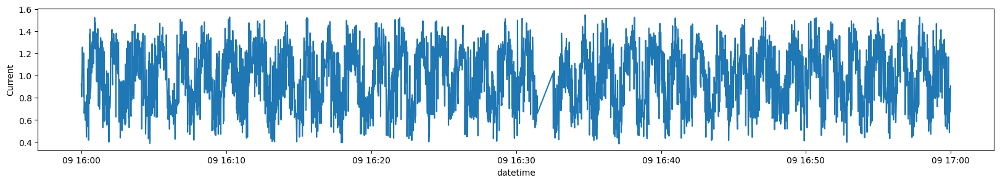

2020-02-08 16


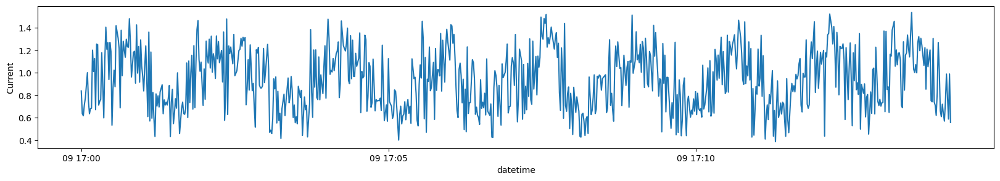

2020-02-08 16


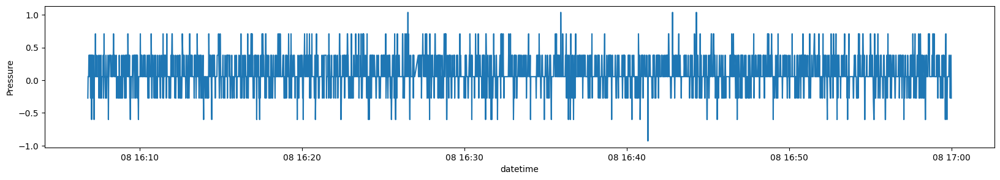

2020-02-08 16


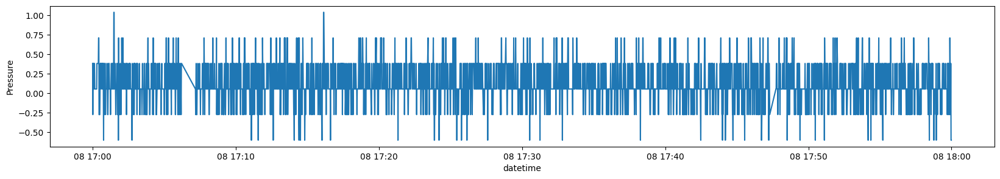

2020-02-08 16


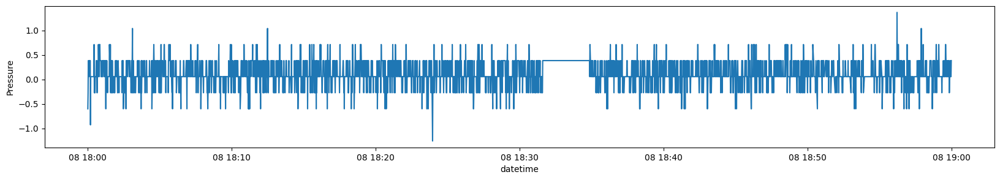

2020-02-08 16


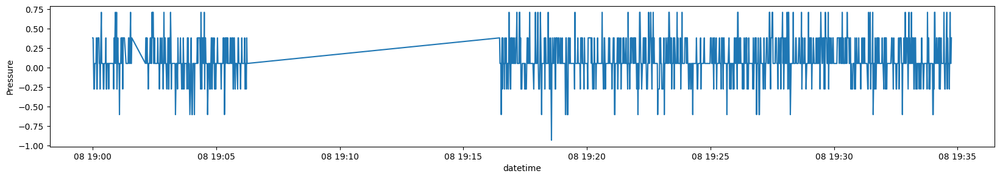

2020-02-08 16


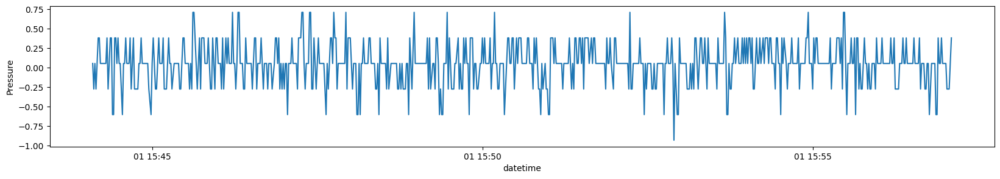

2020-02-08 16


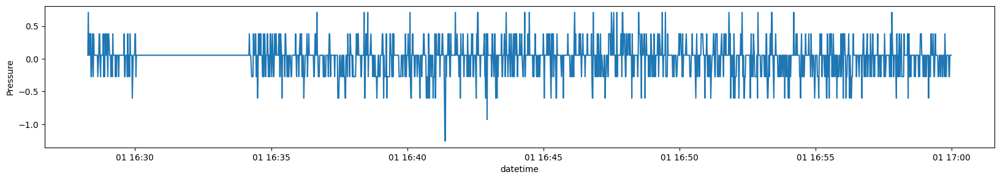

2020-02-08 16


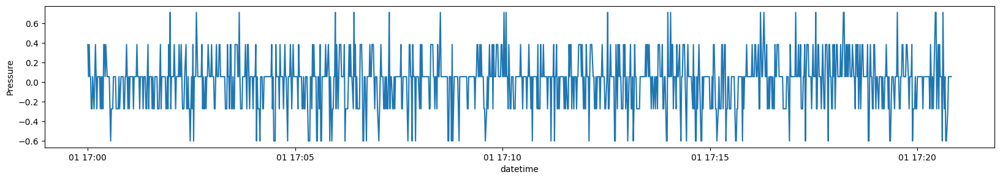

2020-02-08 16


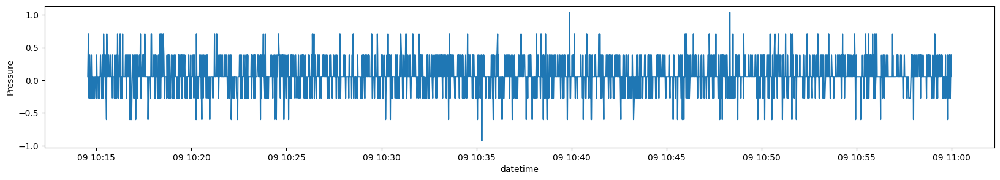

2020-02-08 16


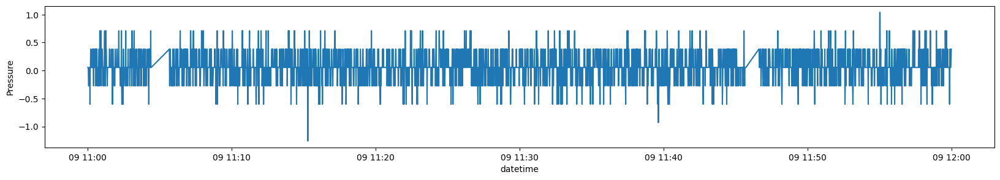

2020-02-08 16


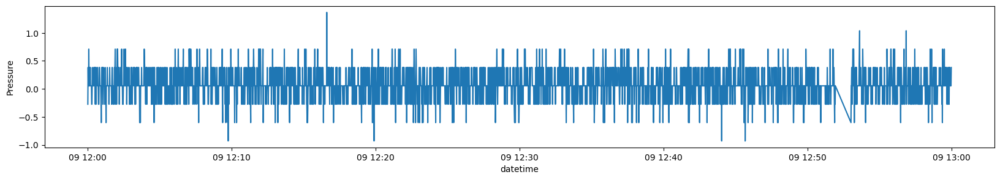

2020-02-08 16


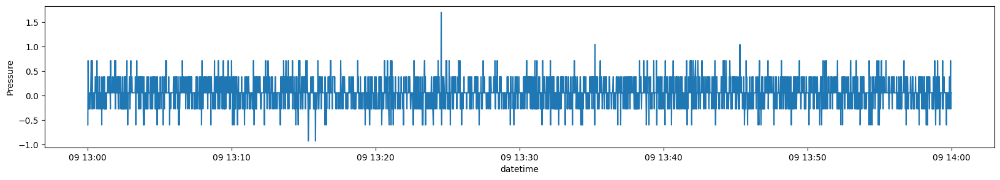

2020-02-08 16


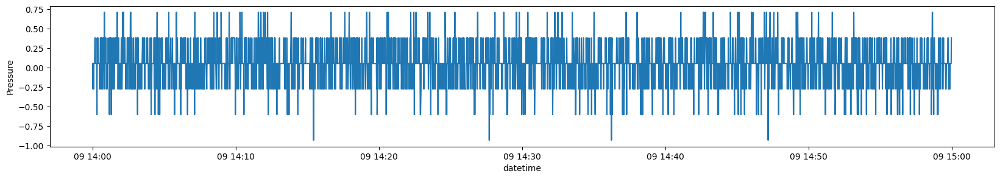

2020-02-08 16


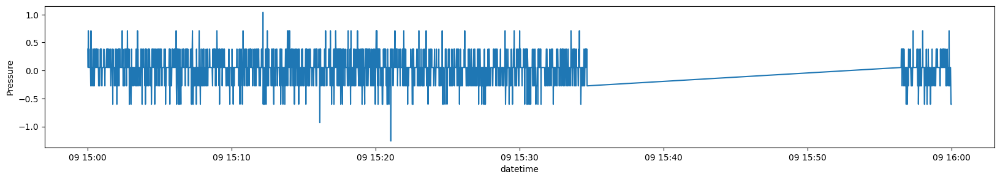

2020-02-08 16


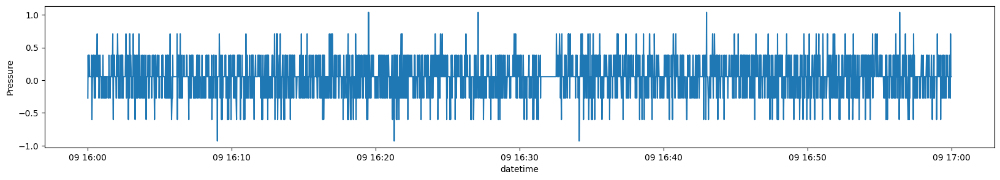

2020-02-08 16


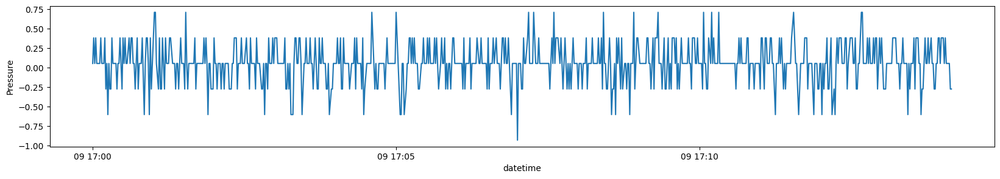

2020-02-08 16


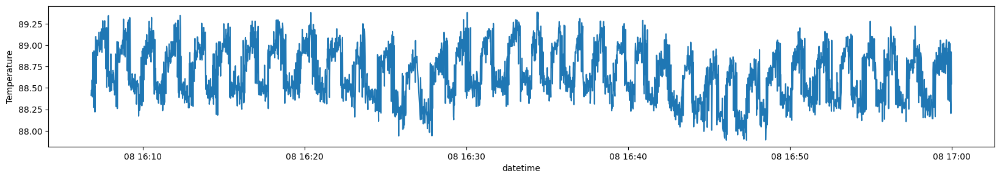

2020-02-08 16


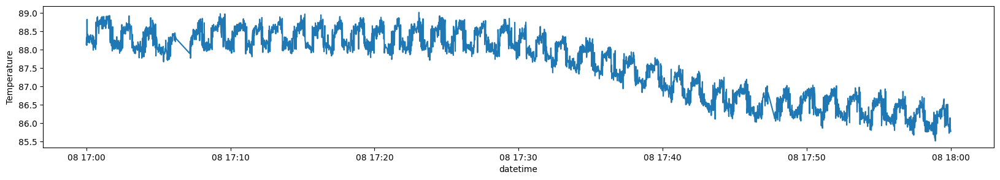

2020-02-08 16


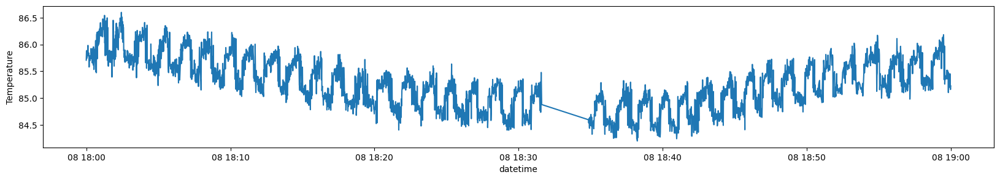

2020-02-08 16


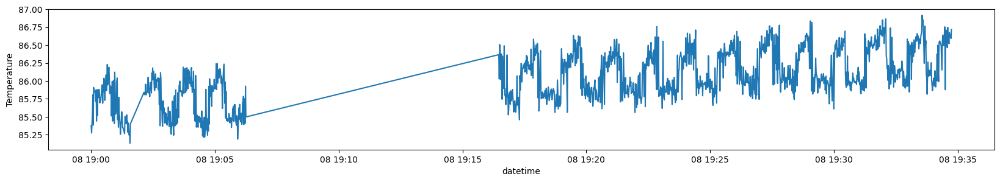

2020-02-08 16


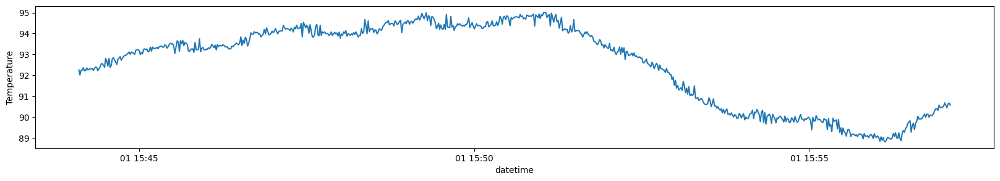

2020-02-08 16


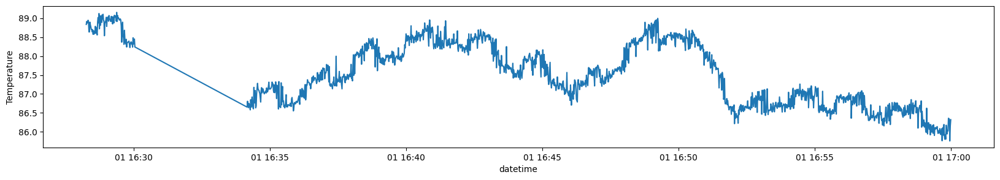

2020-02-08 16


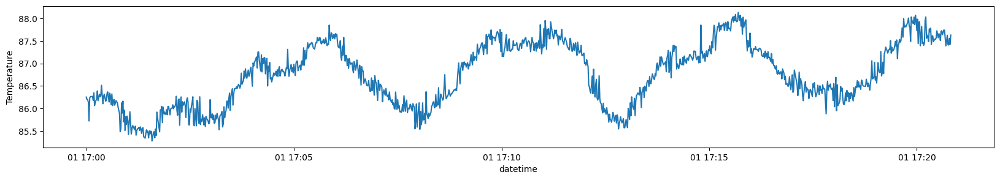

2020-02-08 16


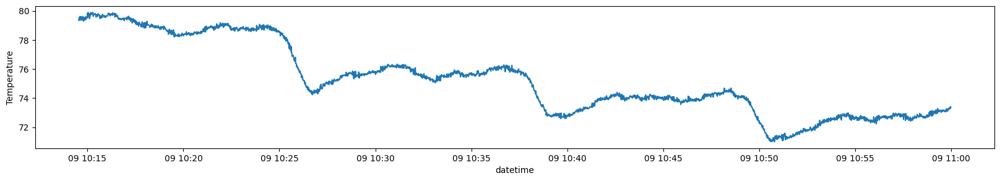

2020-02-08 16


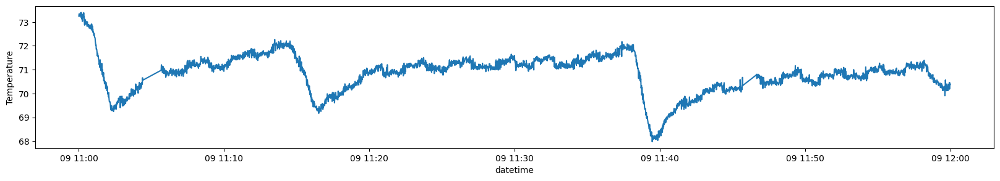

2020-02-08 16


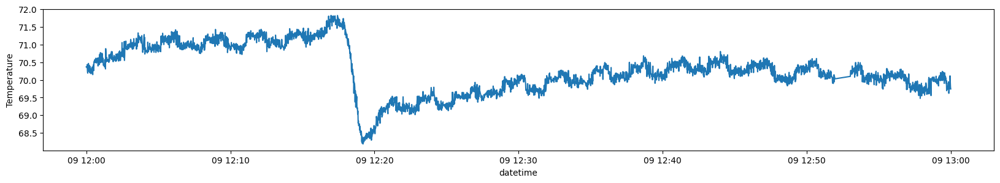

2020-02-08 16


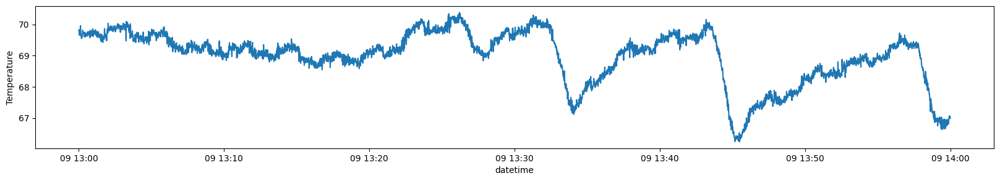

2020-02-08 16


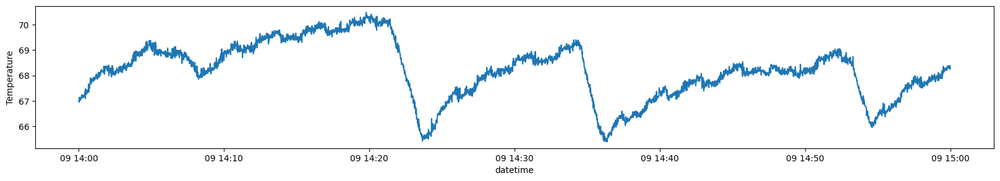

2020-02-08 16


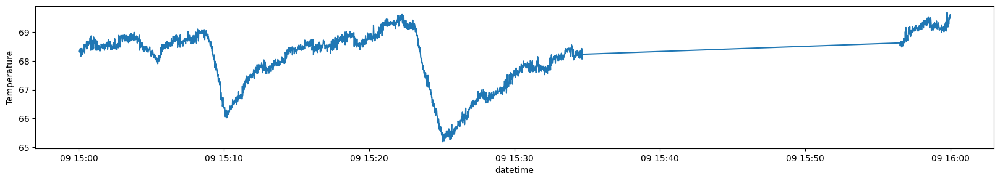

2020-02-08 16


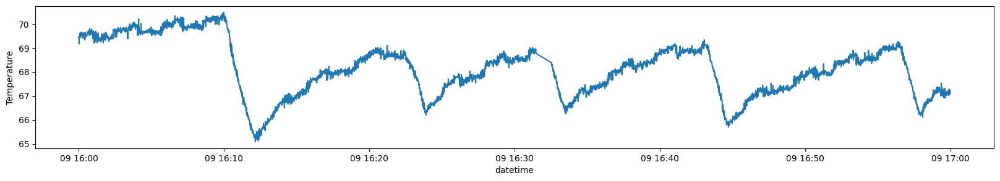

2020-02-08 16


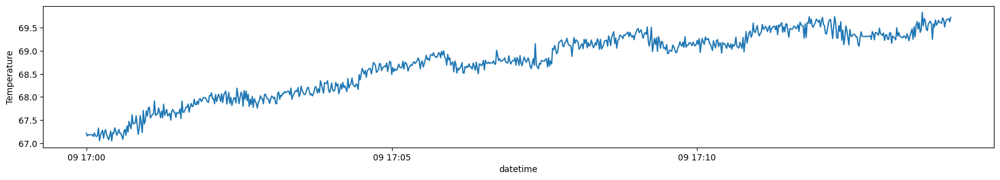

2020-02-08 16


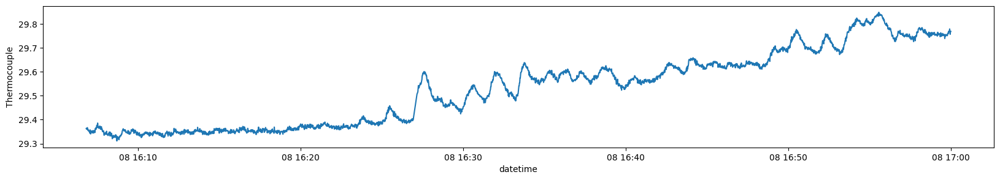

2020-02-08 16


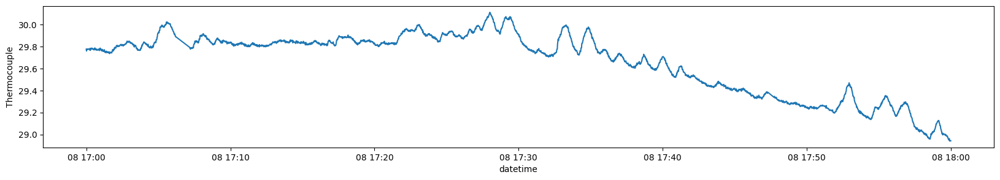

2020-02-08 16


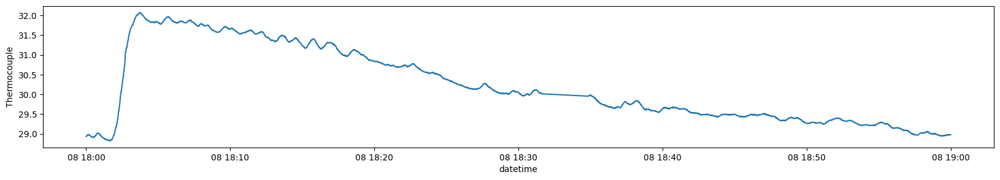

2020-02-08 16


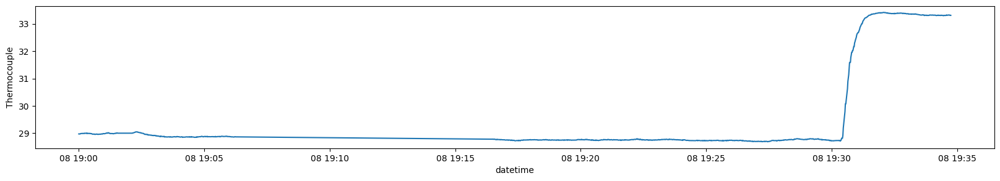

2020-02-08 16


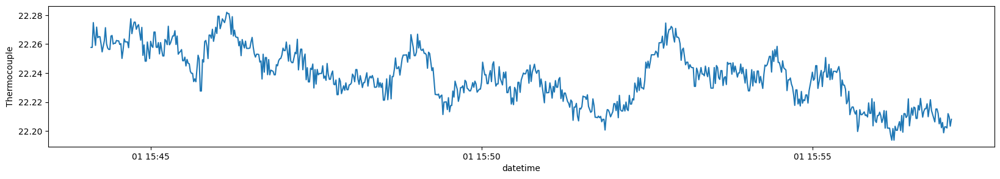

2020-02-08 16


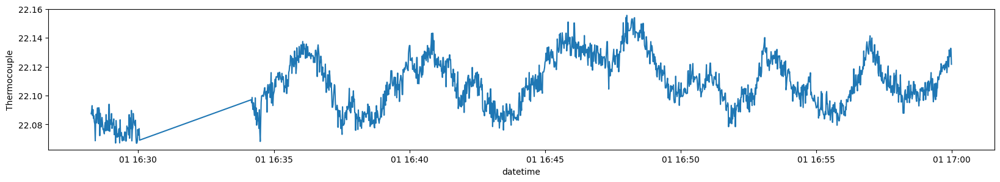

2020-02-08 16


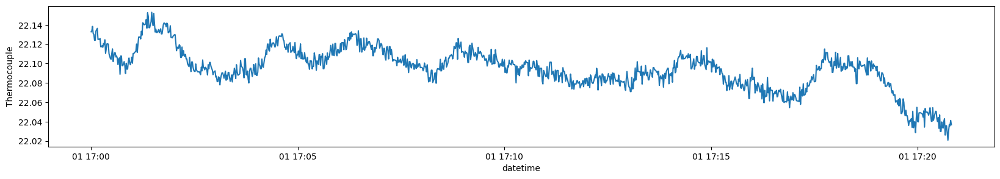

2020-02-08 16


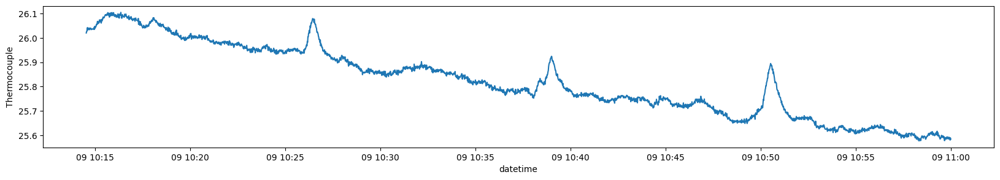

2020-02-08 16


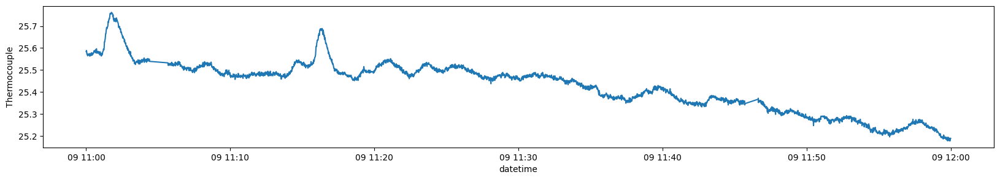

2020-02-08 16


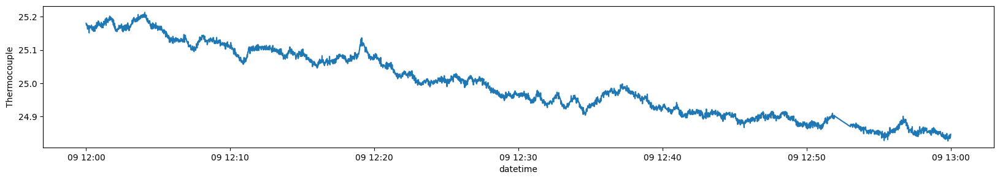

2020-02-08 16


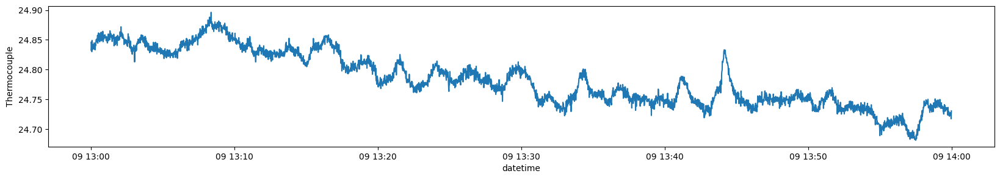

2020-02-08 16


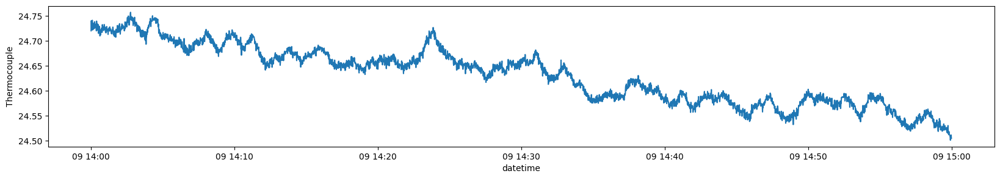

2020-02-08 16


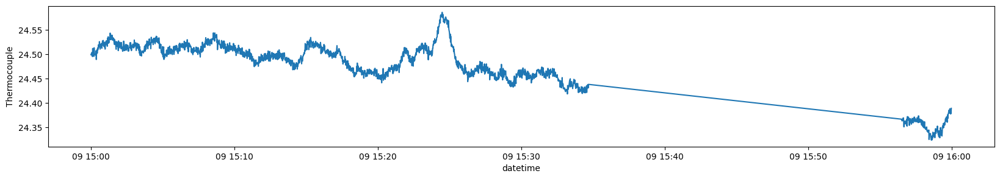

2020-02-08 16


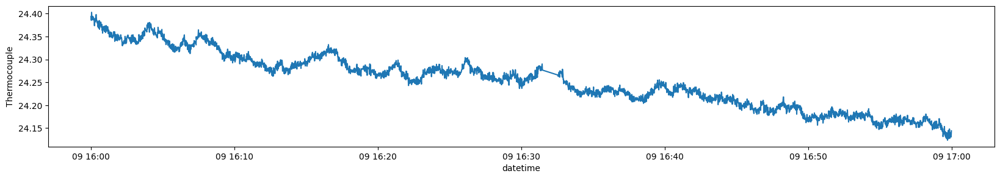

2020-02-08 16


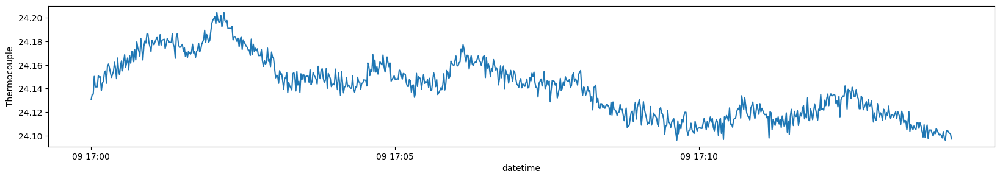

2020-02-08 16


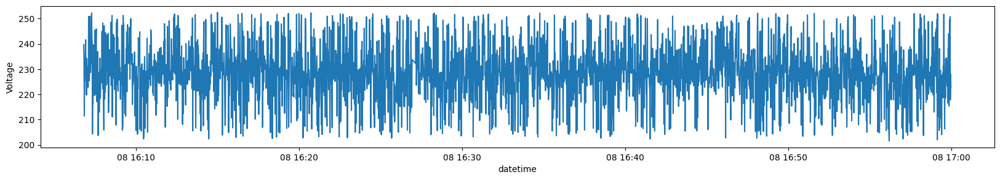

2020-02-08 16


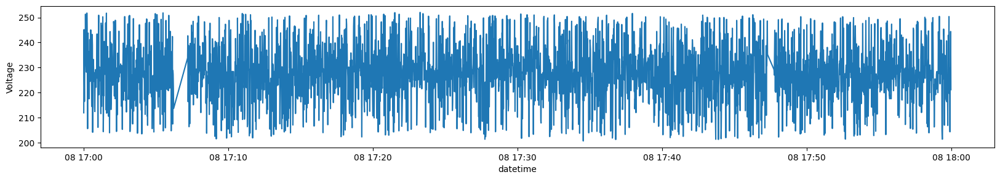

2020-02-08 16


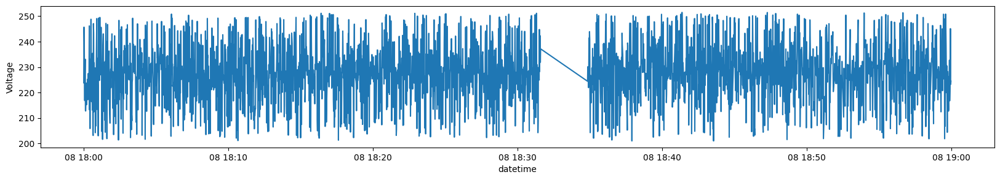

2020-02-08 16


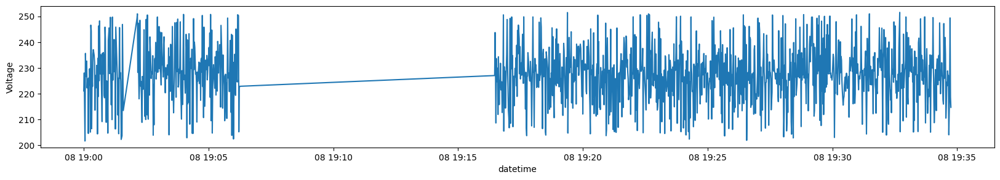

2020-02-08 16


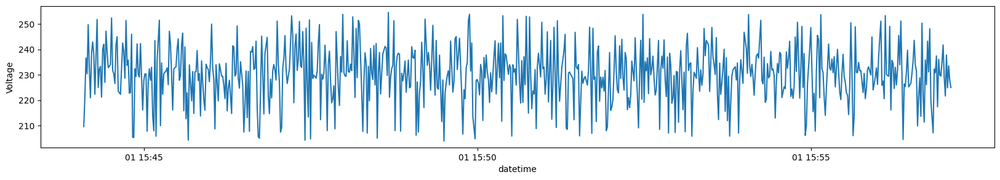

2020-02-08 16


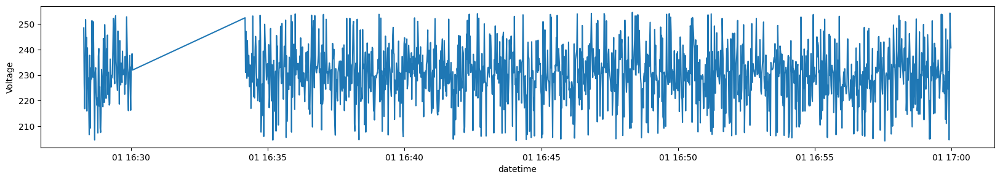

2020-02-08 16


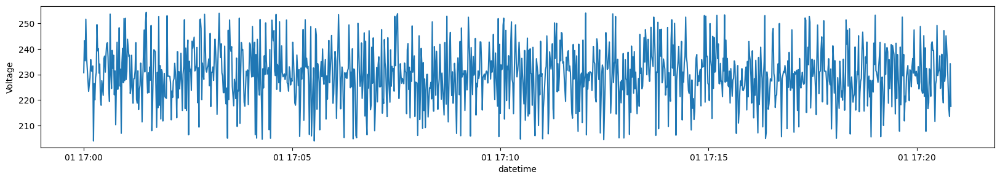

2020-02-08 16


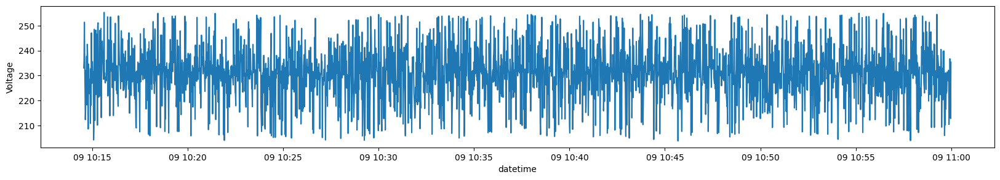

2020-02-08 16


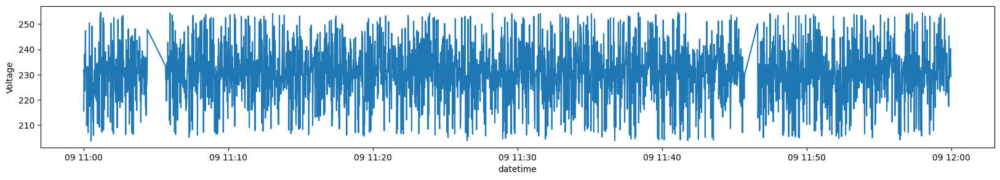

2020-02-08 16


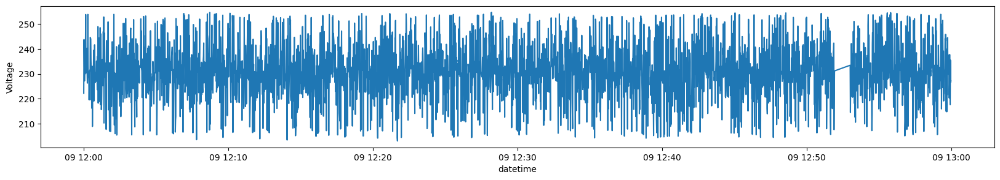

2020-02-08 16


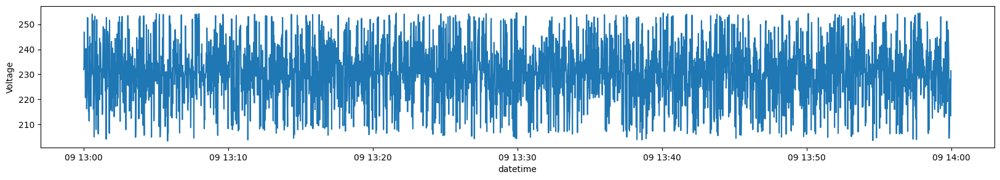

2020-02-08 16


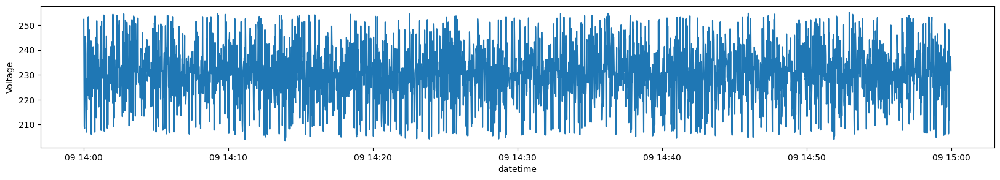

2020-02-08 16


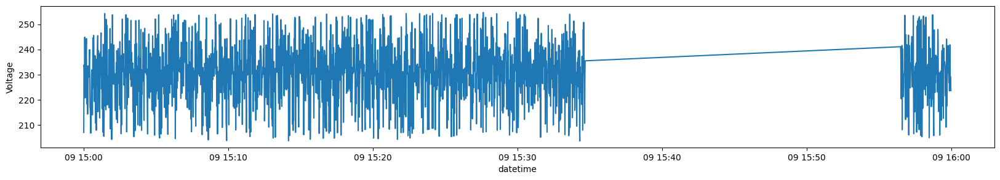

2020-02-08 16


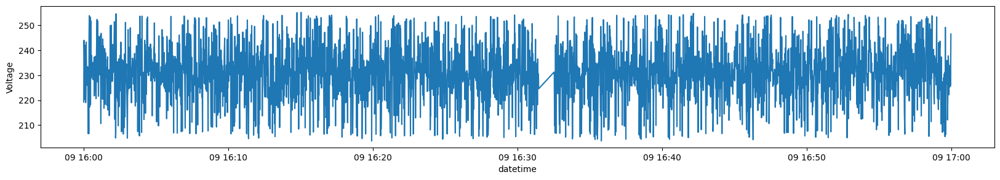

2020-02-08 16


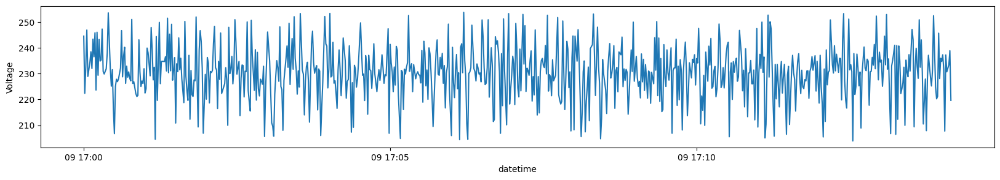

2020-02-08 16


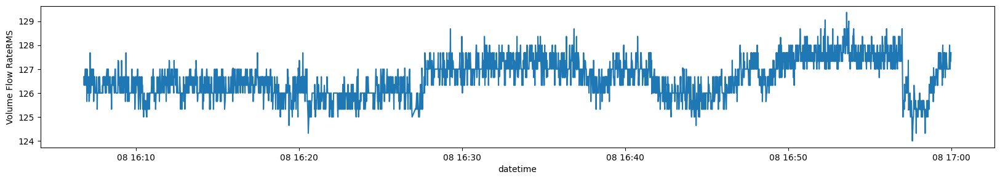

2020-02-08 16


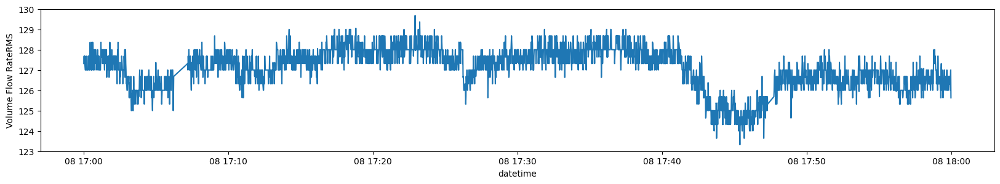

2020-02-08 16


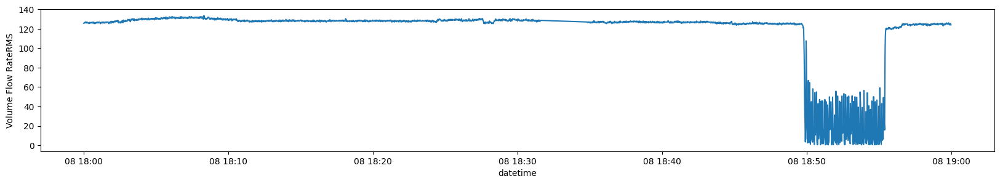

2020-02-08 16


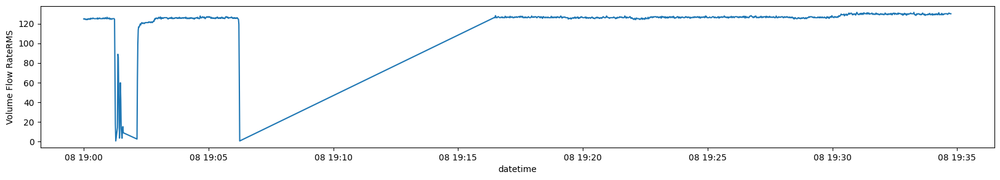

2020-02-08 16


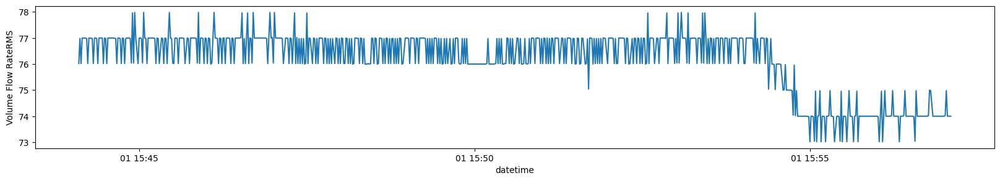

2020-02-08 16


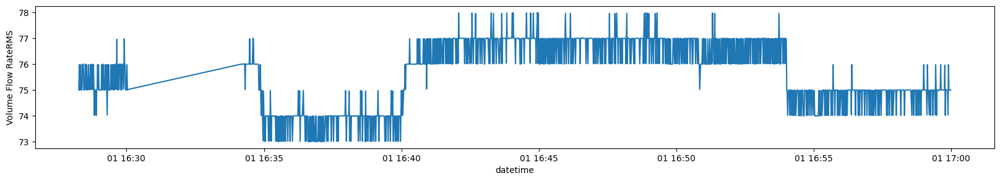

2020-02-08 16


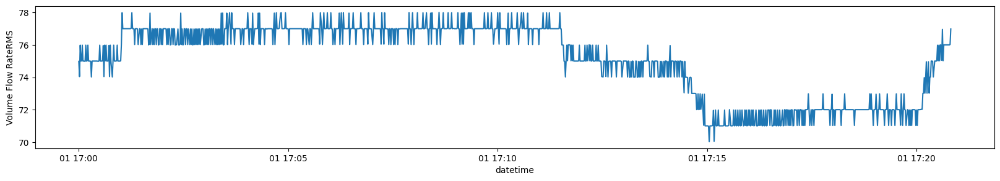

2020-02-08 16


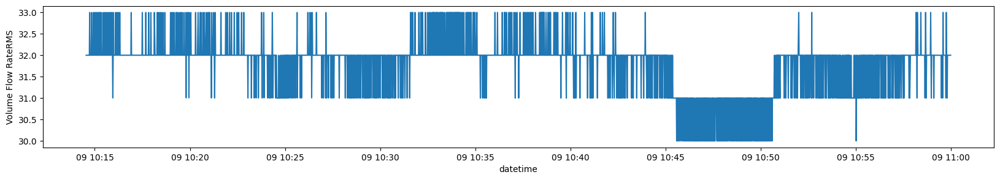

2020-02-08 16


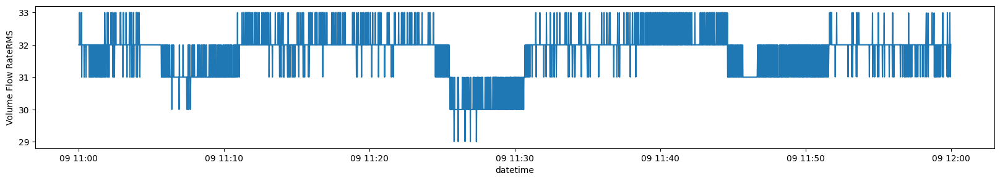

2020-02-08 16


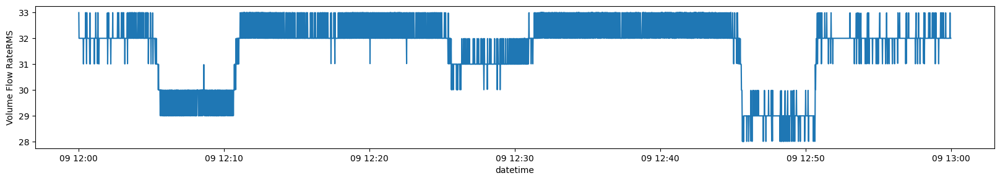

2020-02-08 16


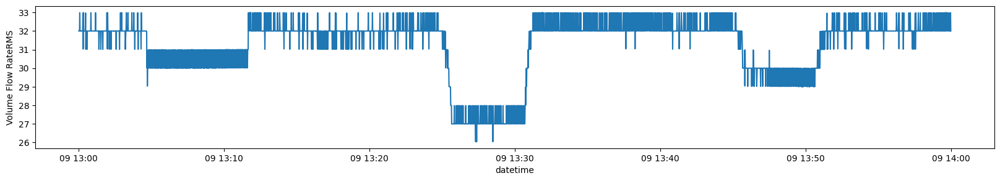

2020-02-08 16


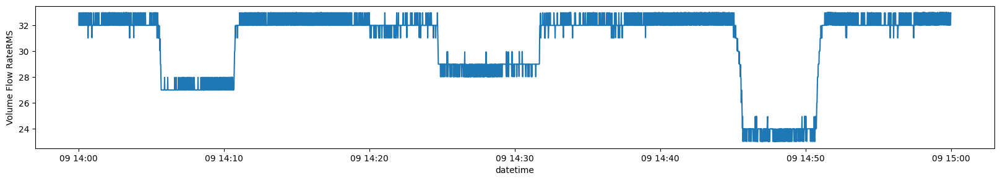

2020-02-08 16


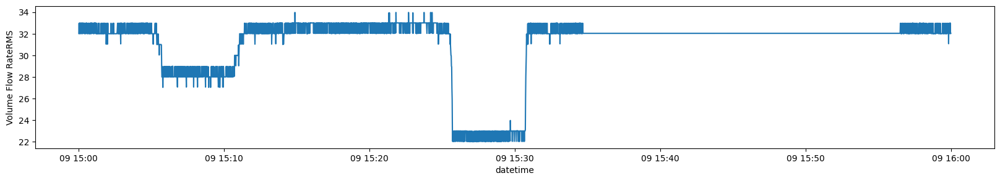

2020-02-08 16


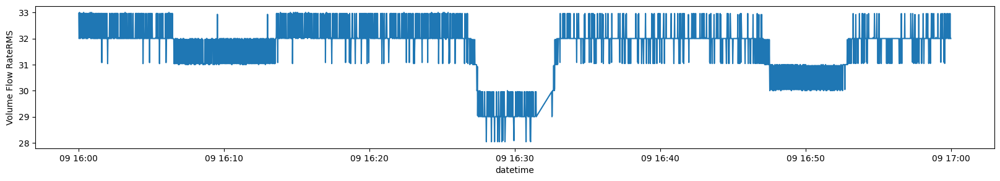

2020-02-08 16


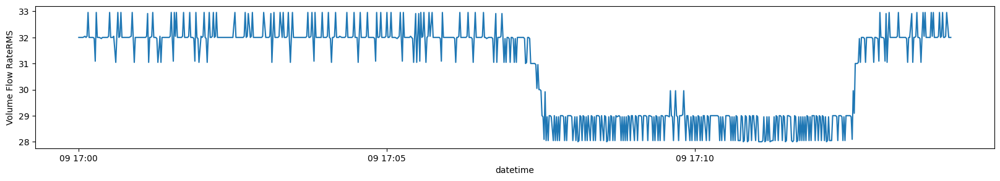

In [ ]:
for c in skab3.columns[1:-2]:
    for i in range(len(day_hour)):
        print(day_hour[0][0], day_hour[0][1])
        eda.plot_features(
            skab3.loc[
                (skab3.datetime.dt.date==day_hour[i][0])&
                (skab3.datetime.dt.hour==day_hour[i][1]),
                ['datetime', c]]
        )

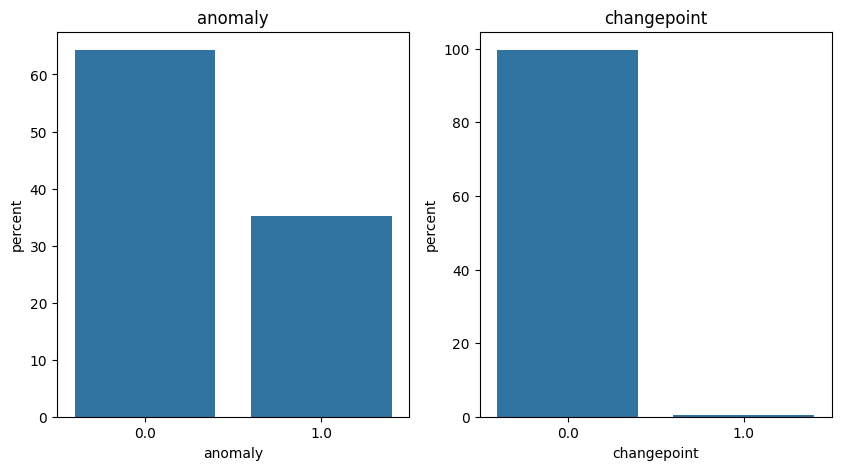

In [ ]:
# Binary features

eda.binary(skab3)

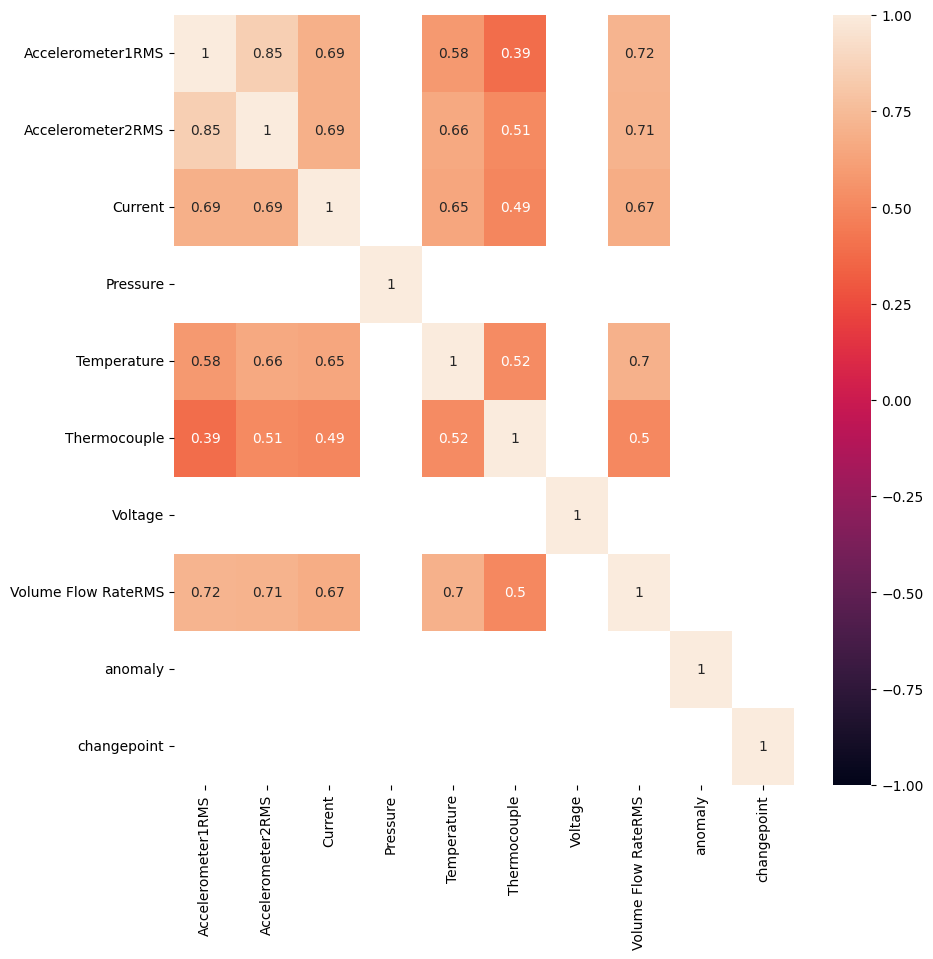

In [ ]:
# Correlations

eda.plot_heatmap(skab3.iloc[:,1:])

In [ ]:
# Stationarity check

In [ ]:
eda.stationarity(skab3)

Accelerometer1RMS: ADF: 0.0005734298958912868, KPSS: 0.01
Accelerometer2RMS: ADF: 0.001218071694001509, KPSS: 0.01
Current: ADF: 0.00047607203060244047, KPSS: 0.01
Pressure: ADF: 0.0, KPSS: 0.01
Temperature: ADF: 0.5876370318681705, KPSS: 0.01
Thermocouple: ADF: 0.1448537812537457, KPSS: 0.01
Voltage: ADF: 0.0, KPSS: 0.01
Volume Flow RateRMS: ADF: 0.23924190206780893, KPSS: 0.01


## Conclusions and next steps

Continuous features:

*   Seasonality is visible for Current and Temperature features, however the patterns are not consistent throughout all days
*   Decreasing trend is present in all features
*   All distributions are skewed with voltage as the only exception
*   All continuous features, except voltage and pressure, are correlated to one another
*   Statistical tests confirm lack of stationarity


Binary features:

*   Anomaly variable is slightly imbalanced with 65%/35% split for 0/1.
*   Changepoint variable is higly imbalanced with almost 100% of points being not a changepoint
*   Both binary features are not correlated with others

#### Handling missing dates

In [ ]:
# Counting missing timestamps

for day, m in eda.count_missing(skab3).items():
    print(f'{day}: {len(eda.count_missing(skab3)[day])}')

2020-02-08: 1594
2020-03-01: 430
2020-03-09: 2705


Missing dates and related data will not be imputted due to:

*   Amount of missing dates is significant and imputation may cause bias
*   Size of the dataset should be enough to train a model
*   Data will be later reduced in the dimension, therefore seasonalities and patterns will be mixed in each component
*   Missing periods are the same for every variable

#### Handling NaNs

In [ ]:
skab3.isna().sum()/len(skab3)

datetime               0.000000
Accelerometer1RMS      0.000000
Accelerometer2RMS      0.000000
Current                0.000000
Pressure               0.000000
Temperature            0.000000
Thermocouple           0.000000
Voltage                0.000000
Volume Flow RateRMS    0.000000
anomaly                0.005968
changepoint            0.000054
dtype: float64

In [ ]:
skab3.loc[skab3['anomaly'].isna(),:]

,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
18318,2020-02-08 18:47:29,0.243698,0.293689,2.82553,0.382638,85.5950,29.4542,222.570,125.69100,NaN,0.0
18320,2020-02-08 18:47:30,0.243417,0.288178,2.92453,0.054711,85.5621,29.4521,233.630,125.31100,NaN,0.0
18322,2020-02-08 18:47:31,0.241315,0.289644,3.03341,0.054711,85.3922,29.4462,244.891,125.00000,NaN,0.0
18324,2020-02-08 18:47:32,0.244141,0.292917,2.38993,-0.273216,85.6120,29.4428,220.101,125.69100,NaN,0.0
18326,2020-02-08 18:47:33,0.241652,0.288655,2.61289,-0.273216,85.7253,29.4463,240.418,125.31100,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...
18748,2020-02-08 18:51:47,0.257902,0.296805,2.99999,0.382638,85.8045,29.3638,234.738,11.63290,NaN,0.0
18750,2020-02-08 18:51:48,0.258294,0.299514,2.75747,0.382638,85.7575,29.3644,240.654,49.63930,NaN,0.0
18752,2020-02-08 18:51:49,0.267134,0.306197,2.19596,0.382638,85.0245,29.3574,243.878,35.41700,NaN,0.0
18754,2020-02-08 18:51:50,0.260644,0.300924,2.16641,0.054711,85.4640,29.3704,227.270,8.94094,NaN,0.0


In [ ]:
min2, sec2 = eda.show_time(skab3.loc[skab3['anomaly'].isna(),['datetime']])

Hour/minute:
18: [47, 48, 49, 50, 51]
Hour/#seconds:
18:             [30, 57, 56, 41, 36]


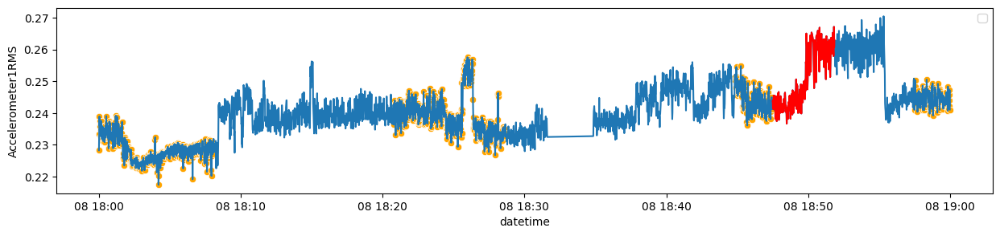

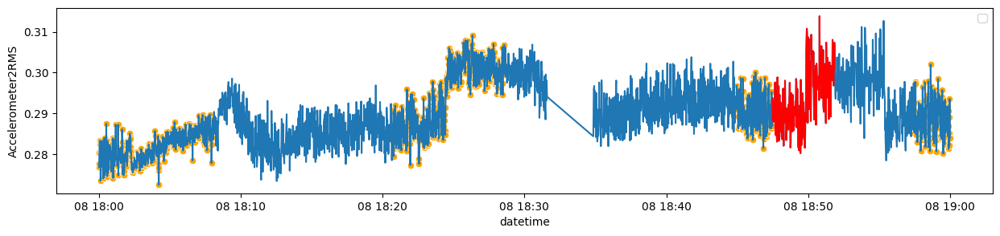

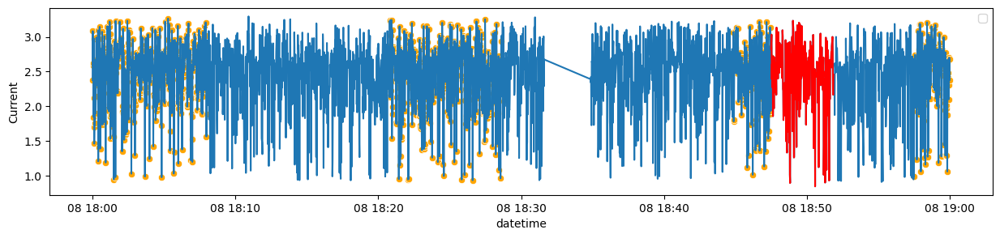

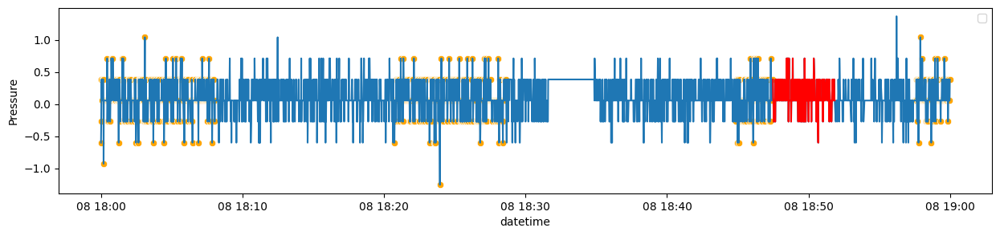

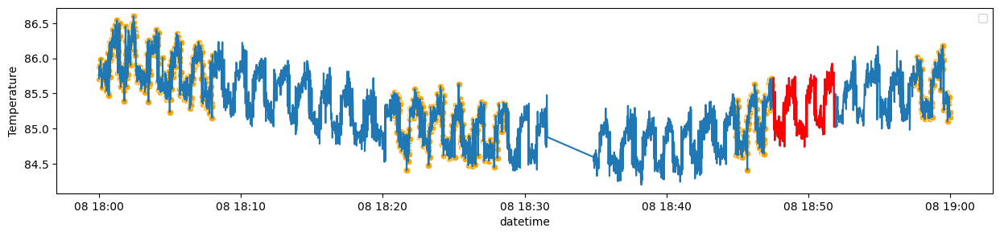

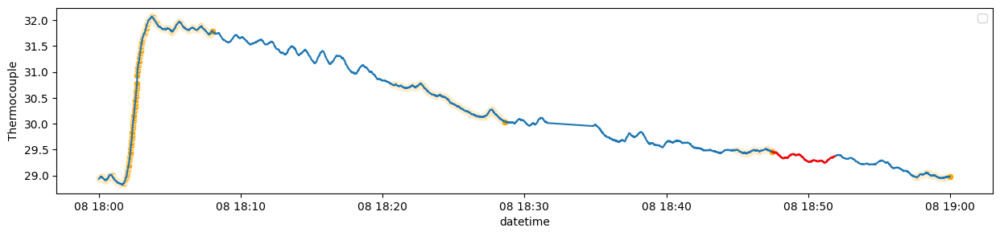

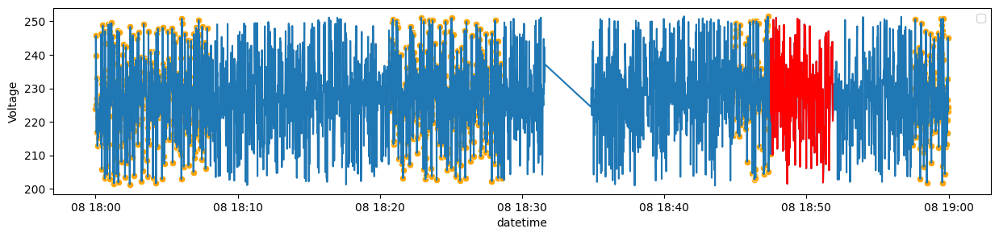

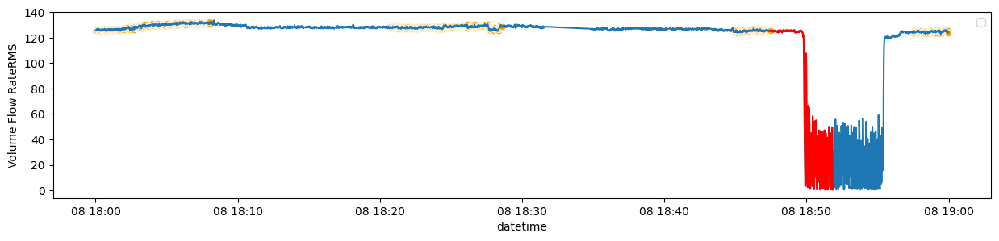

In [ ]:
for f in skab3.columns[1:-2]:
    plt.figure(figsize=(15,3))
    sns.lineplot(data=skab3.loc[(skab3.datetime.dt.date==datetime.date(2020,2,8))&
    (skab3.datetime.dt.hour==18),:], y=f, x='datetime')
    sns.scatterplot(data=skab3.loc[(skab3.datetime.dt.date==datetime.date(2020,2,8))&
    (skab3.datetime.dt.hour==18)&(skab3.anomaly == 1),:], y=f, x='datetime', color = 'orange')
    sns.lineplot(data=skab3.loc[(skab3.datetime.dt.date==datetime.date(2020,2,8))&
    (skab3.datetime.dt.hour==18)&
    (skab3['anomaly'].isna()),:], y=f, x='datetime', color='red')
    plt.legend(loc='upper right')
plt.show()

*   It is not obvious when anomaly occurs looking at values of each particular variable
*   Missing values' count in the anomaly column is not significant


Due to Temperature variable is seasonal, seasonal window containing NaNs will be removed from the dataset

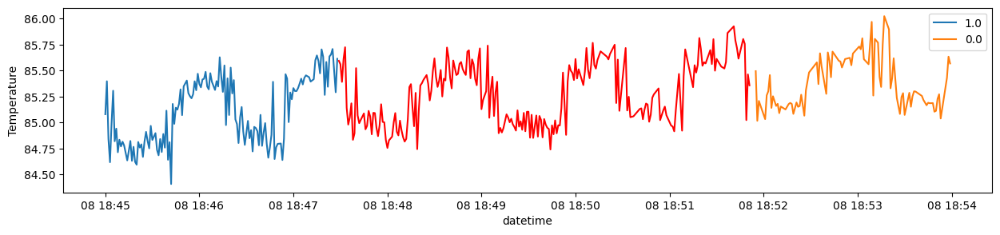

In [ ]:
filter = (skab3.datetime.dt.date==datetime.date(2020,2,8))&(skab3.datetime.dt.hour==18)&(skab3.datetime.dt.minute.isin(np.arange(45,54)))
f = 'Temperature'
plt.figure(figsize=(15,3))
sns.lineplot(data=skab3.loc[filter,:], y=f, x='datetime', hue='anomaly')
sns.lineplot(data=skab3.loc[filter&
(skab3['anomaly'].isna()),:], y=f, x='datetime', color='red')
plt.legend()
plt.show()

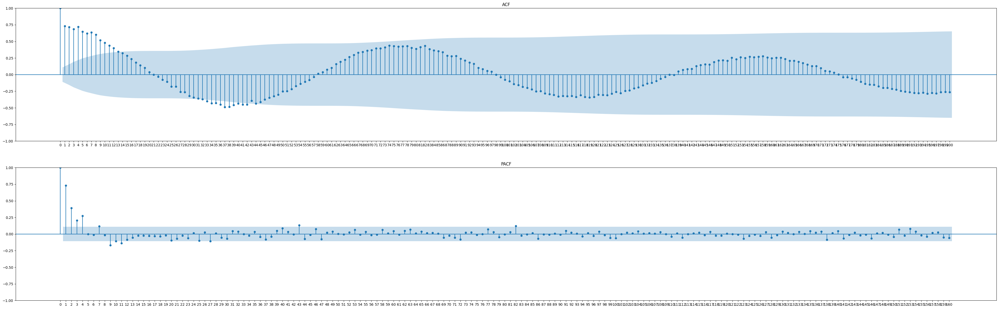

In [ ]:
fig, ax = plt.subplots(2,1, figsize = (50,15))
ax[0].set_xticks(np.arange(0,200+1,1))
plot_acf(skab3.loc[filter,f][:-120], lags = 200, ax = ax[0], title = f'ACF')
ax[1].set_xticks(np.arange(0,160+1,1))
plot_pacf(skab3.loc[filter,f][:-120], lags = 160, ax = ax[1], title = f'PACF')

plt.show()

Seasonal period is between 78-81 lags.

In [ ]:
len(skab3.loc[(skab3['anomaly'].isna()),:]), 80*3

(220, 240)

In [ ]:
location=skab3.loc[skab3.anomaly.isna(),:].index.tolist()
absolute_indices = [skab3.index.get_loc(label) for label in location]
absolute_indices.extend(np.arange(absolute_indices[-1]+1,absolute_indices[-1]+21))

In [ ]:
skab4 = pd.concat([skab3.iloc[:absolute_indices[0],:], skab3.iloc[(absolute_indices[-1]+1):,:]])

In [ ]:
# Changepoint

skab4.loc[skab4['changepoint'].isna(),:]

,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint


#### Train test val split

In [ ]:
skab4 = skab4.set_index('datetime')

In [ ]:
# Test/validation length: 15 min

l = int(15*60)

In [ ]:
train, val = skab4.iloc[:-l], skab4.iloc[-l:,:]
train, test = train.iloc[:-l], train.iloc[-l:,:]

X_train, X_test, X_val = train.loc[:, ~train.columns.isin(['anomaly'])], test.loc[:, ~test.columns.isin(['anomaly'])], val.loc[:, ~val.columns.isin(['anomaly'])]
y_train, y_test, y_val = train.loc[:, 'anomaly'].astype(int), test.loc[:, 'anomaly'].astype(int), val.loc[:, 'anomaly'].astype(int)

#### Dimensionality reduction

In [ ]:
# Choosing the best number of components
pca = PCA(n_components=len(X_train.columns), random_state=42)

pipe_dr = Pipeline([
    ('scaler', MinMaxScaler()),
    ('dr', pca)
])

pipe_dr.fit(X_train)

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('dr', PCA(n_components=9, random_state=42))])

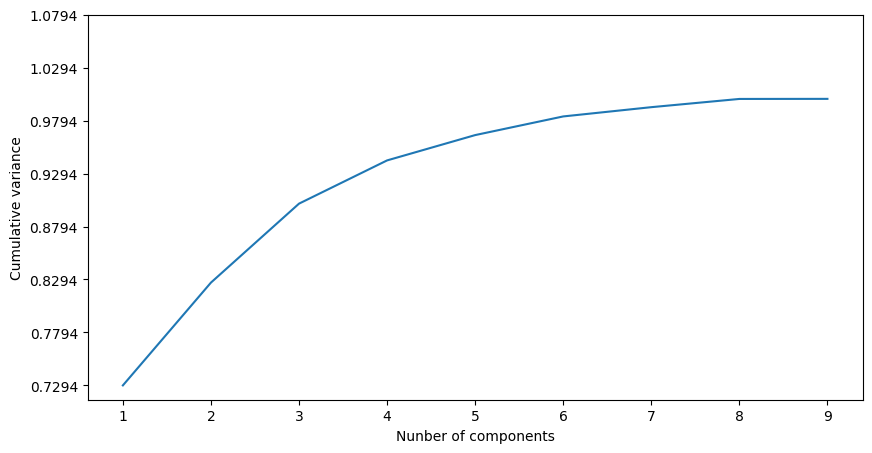

In [ ]:
# Plotting cumulative variance vs number of components

eda.plot_comp(pipe_dr.named_steps['dr'], len(X_train.columns))

4 components explain over 92% of the variance which should be enough.

In [ ]:
np.set_printoptions(suppress=True, precision=6)

In [ ]:
pipe_dr.set_params(dr__n_components=4)

pipe_dr.fit(X_train)

pd.DataFrame(pipe_dr.named_steps['dr'].components_, columns = X_train.columns, index = ['PC'+str(i) for i in range(1,5)])

,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,changepoint
PC1,0.303088,0.317825,0.402972,0.012634,0.471827,0.324625,-0.031083,0.561792,-0.000049
PC2,-0.048895,-0.046998,0.273020,-0.004730,-0.006713,-0.066715,0.956164,-0.045672,-0.002480
PC3,0.222958,0.165542,0.029849,0.038363,-0.669398,0.682308,0.050987,-0.065454,0.000439
PC4,0.596805,0.593897,-0.326564,-0.018504,-0.005202,-0.357458,0.118061,-0.205852,0.002608


*   Component 1 is mainly influenced by all highly correlated variables
*   Component 2 is mainly influenced by Voltage
*   Component 3 is mainly influenced by temperature-related variables
*   Component 4 is mainly influenced by Accelerometer variables

In [ ]:
pd.DataFrame(pipe_dr.transform(X_train)).apply([min, max])

,0,1,2,3
min,-0.629099,-0.644269,-0.677079,-0.283979
max,1.246384,0.528334,0.314910,0.761697


Range of every components is between -1 and 1.25

#### Dummy classification

In [ ]:
dummy = DummyClassifier(random_state=42)

pipe_dummy = deepcopy(pipe_dr)
pipe_dummy.steps.append(
    ('dummy', dummy)
)
pipe_dummy.fit(X_train, y_train)

dummy_score_test = f1_score(y_test, pipe_dummy.predict(X_test))

print(f'Dummy classifier score: {dummy_score_test}')

Dummy classifier score: 0.0


Dummy classifier has 0 score on the test set.

# **2. Supervised learning**

For forecasting, 3 models will be trained and evaluated on test set:
*   Random Forest
*   SVM
*   LSTM

Results will be measured by F1 score, which combines measures of how well model captures anomalies and how many it misses.

### **Random Forest**

In [ ]:
l/len(X_train)

0.025846471956577927

In [ ]:
window = len(X_train)- 10*900

#### **Baseline model**

In [ ]:
# CV splitter: 10 folds, step = 15 min
splitter = SlidingWindowSplitter(fh=range(1,l+1), step_length=900, window_length=window)
cv = []
for i,j in splitter.split(X_train):
    cv.append((i,j))
len(cv)

10

In [ ]:
pipe_rf = deepcopy(pipe_dr)
pipe_rf.steps.append(
    ('rf', RandomForestClassifier(random_state=42))
)

In [ ]:
# CV score for baseline model
cv_rf1 = np.mean(cross_val_score(pipe_rf, X_train, y_train, cv = cv, scoring = 'f1'))

print(f'CV score - baseline: {cv_rf1}')




CV score - baseline: 0.4309764957648703


In [ ]:
# Fitting on test set

pipe_rf.fit(X_train, y_train)
score_rf1 = f1_score(y_test, pipe_rf.predict(X_test))

print(f'RF test score - baseline: {score_rf1}')


RF test score - baseline: 0.4666666666666667


Test score for default Random Forest is around 0.47.

#### **Optimization**

In [ ]:
# Optimization of hyperparameters and evaluation on the test set

score_rf2, pred_rf2, pipe_rf2, par_rf2, cv_rf2 = training.train(30, cv_rf1, pipe_rf, X_train, y_train, X_test, y_test, 'rf', cv)

Optimization with baseline 0.4309764957648703
Optimization completed



In [ ]:
print(f'CV score: {cv_rf2}\nTest score: {score_rf2}\nBest params: {par_rf2}')

CV score: 0.4503291376966067
Test score: 0.40816326530612246
Best params: {'rf__n_estimators': 459, 'rf__max_depth': 60, 'rf__min_samples_split': 36, 'rf__min_samples_leaf': 15, 'rf__max_features': 4, 'rf__random_state': 42, 'rf__n_jobs': -1, 'rf__verbose': 0}


CV score for tuned model is better, however performance on the test set is lower than the default case.

### **SVM**

#### **Baseline model**

In [ ]:
y_train_svm = y_train.copy()
y_train_svm.loc[y_train==0]=-1

y_test_svm = y_test.copy()
y_test_svm.loc[y_test==0]=-1

In [ ]:
pipe_svm = deepcopy(pipe_dr)
pipe_svm.steps.append(
    ('svm', SVC(random_state=42))
)

In [ ]:
# CV score for baseline model
cv_svm1 = np.mean(cross_val_score(pipe_svm, X_train, y_train_svm, cv = cv, scoring = 'f1'))

print(f'CV score - baseline: {cv_svm1}')




CV score - baseline: 0.0


In [ ]:
# Fitting on test set

pipe_svm.fit(X_train, y_train_svm)
score_svm1 = f1_score(y_test_svm, pipe_svm.predict(X_test))

print(f'SVM test score - baseline: {score_svm1}')


SVM test score - baseline: 0.0


Test F1-score for default SVM is 0.

#### **Optimization**

In [ ]:
# Optimization of hyperparameters and evaluation on the test set

score_svm2, pred_svm2, pipe_svm2, par_svm2, cv_svm2 = training.train(30, cv_svm1, pipe_svm, X_train, y_train_svm, X_test, y_test_svm, 'svm', cv)

Optimization with baseline 0.0
Optimization completed



In [ ]:
print(f'CV score: {cv_svm2}\nTest score: {score_svm2}\nBest params: {par_svm2}')

CV score: 0.4623372943873642
Test score: 0.4206730769230769
Best params: {'svm__C': 25.433582398183454, 'svm__kernel': 'sigmoid', 'svm__gamma': 0.6266807412895816, 'svm__degree': 4}


Performance on the test set for the tune model is around 0.42.

### **LSTM**

#### **Baseline model**

In [ ]:
future = ['PC' + str(i) for i in range(1,5)]

In [ ]:
nn = NeuralForecast(
    models = [m.LSTM(h = l, loss = DistributionLoss('Bernoulli'), max_steps = 20, futr_exog_list=future)],
    freq = 1
)

Seed set to 1


In [ ]:
# Fitting on test set

score_lstm1, pred_lstm1 = training.fit_predict_nf(pipe_dr, nn, X_train, y_train, X_test, y_test)

print(f'SVM test score - baseline: {score_lstm1}')

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

SVM test score - baseline: 0.61003861003861


Test F1-score for default LSTM is 0.61 with 20 epochs.

#### **Optimization**

In [ ]:
config_lstm ={
    'input_size':tune.randint(30, l*4),
    'futr_exog_list': future,
    'encoder_n_layers': tune.choice([2,4,8,16]),
    'encoder_hidden_size': tune.choice([32, 64, 128, 256]),
    'encoder_dropout': tune.uniform(0.0,0.2),
    'decoder_hidden_size': tune.choice([32, 64, 128, 256]),
    'decoder_layers': tune.choice([2,4,8,16]),
    'max_steps':tune.qrandint(20,50,10),
    'learning_rate':tune.uniform(0.001,0.01),
    'batch_size':tune.choice([1]),
    'windows_batch_size':tune.choice([16, 32, 64, 128]),
    'val_check_steps': tune.choice([5,10, 25]),
    'scaler_type':tune.choice(['minmax','standard','robust']),
    'random_seed':tune.randint(1, 100)
}

In [ ]:
# Optimization of hyperparameters and evaluation on the test set

score_lstm2, pred_lstm2, par_lstm2= training.optim(30, l, pipe_dr, X_train, y_train, X_test, y_test, config_lstm)

(_train_tune pid=20244) c:\Users\krystyna_furgacz1\AppData\Local\Programs\Python\Python311\Lib\site-packages\ray\tune\integration\pytorch_lightning.py:198: `ray.tune.integration.pytorch_lightning.TuneReportCallback` is deprecated. Use `ray.tune.integration.pytorch_lightning.TuneReportCheckpointCallback` instead.
(_train_tune pid=20244) Seed set to 87
(_train_tune pid=20244) GPU available: False, used: False
(_train_tune pid=20244) TPU available: False, using: 0 TPU cores
(_train_tune pid=20244) HPU available: False, using: 0 HPUs
(_train_tune pid=20244) 
(_train_tune pid=20244)   | Name              | Type             | Params | Mode 
(_train_tune pid=20244) ---------------------------------------------------------------
(_train_tune pid=20244) 0 | loss              | DistributionLoss | 5      | train
(_train_tune pid=20244) 1 | padder_train      | ConstantPad1d    | 0      | train
(_train_tune pid=20244) 2 | scaler            | TemporalNorm     | 0      | train
(_train_tune pid=20244)

Epoch 9: 100%|██████████| 1/1 [00:01<00:00,  0.68it/s, v_num=0, train_loss_step=0.648, train_loss_epoch=0.663]
Validation: |          | 0/? [00:00<?, ?it/s]
Validation DataLoader 0:   0%|          | 0/1 [00:00<?, ?it/s]
(_train_tune pid=20244) 
Epoch 19: 100%|██████████| 1/1 [00:01<00:00,  0.71it/s, v_num=0, train_loss_step=0.646, train_loss_epoch=0.658, valid_loss=0.664]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 29: 100%|██████████| 1/1 [00:01<00:00,  0.70it/s, v_num=0, train_loss_step=0.646, train_loss_epoch=0.646, valid_loss=0.661]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 39:   0%|          | 0/1 [00:00<?, ?it/s, v_num=0, train_loss_step=0.645, train_loss_epoch=0.645, valid_loss=0.659]        


(_train_tune pid=20244) `Trainer.fit` stopped: `max_steps=40` reached.


Epoch 39: 100%|██████████| 1/1 [00:01<00:00,  0.87it/s, v_num=0, train_loss_step=0.667, train_loss_epoch=0.645, valid_loss=0.659]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 39: 100%|██████████| 1/1 [00:01<00:00,  0.84it/s, v_num=0, train_loss_step=0.667, train_loss_epoch=0.667, valid_loss=0.662]


(_train_tune pid=2880) c:\Users\krystyna_furgacz1\AppData\Local\Programs\Python\Python311\Lib\site-packages\ray\tune\integration\pytorch_lightning.py:198: `ray.tune.integration.pytorch_lightning.TuneReportCallback` is deprecated. Use `ray.tune.integration.pytorch_lightning.TuneReportCheckpointCallback` instead.
(_train_tune pid=2880) Seed set to 35
(_train_tune pid=2880) GPU available: False, used: False
(_train_tune pid=2880) TPU available: False, using: 0 TPU cores
(_train_tune pid=2880) HPU available: False, using: 0 HPUs
(_train_tune pid=2880) 
(_train_tune pid=2880)   | Name              | Type             | Params | Mode 
(_train_tune pid=2880) ---------------------------------------------------------------
(_train_tune pid=2880) 0 | loss              | DistributionLoss | 5      | train
(_train_tune pid=2880) 1 | padder_train      | ConstantPad1d    | 0      | train
(_train_tune pid=2880) 2 | scaler            | TemporalNorm     | 0      | train
(_train_tune pid=2880) 3 | hist_en

...

Epoch 4: 100%|██████████| 1/1 [00:12<00:00,  0.08it/s, v_num=0, train_loss_step=0.503, train_loss_epoch=0.520]
Validation: |          | 0/? [00:00<?, ?it/s]
Validation DataLoader 0:   0%|          | 0/1 [00:00<?, ?it/s]
(_train_tune pid=13704) 
Epoch 9: 100%|██████████| 1/1 [00:11<00:00,  0.09it/s, v_num=0, train_loss_step=0.399, train_loss_epoch=0.416, valid_loss=0.478]
Validation: |          | 0/? [00:00<?, ?it/s]
Validation DataLoader 0:   0%|          | 0/1 [00:00<?, ?it/s]
(_train_tune pid=13704) 
Epoch 14: 100%|██████████| 1/1 [00:11<00:00,  0.09it/s, v_num=0, train_loss_step=0.244, train_loss_epoch=0.273, valid_loss=0.362]
Validation: |          | 0/? [00:00<?, ?it/s]
Validation DataLoader 0:   0%|          | 0/1 [00:00<?, ?it/s]
(_train_tune pid=13704) 
Epoch 19: 100%|██████████| 1/1 [00:11<00:00,  0.09it/s, v_num=0, train_loss_step=0.179, train_loss_epoch=0.160, valid_loss=0.205]
Validation: |          | 0/? [00:00<?, ?it/s]
Validation DataLoader 0:   0%|          | 0/1 [00:00

(_train_tune pid=13704) `Trainer.fit` stopped: `max_steps=40` reached.


(_train_tune pid=13704) 
Epoch 39: 100%|██████████| 1/1 [00:11<00:00,  0.09it/s, v_num=0, train_loss_step=0.153, train_loss_epoch=0.153, valid_loss=0.148]


(_train_tune pid=34752) c:\Users\krystyna_furgacz1\AppData\Local\Programs\Python\Python311\Lib\site-packages\ray\tune\integration\pytorch_lightning.py:198: `ray.tune.integration.pytorch_lightning.TuneReportCallback` is deprecated. Use `ray.tune.integration.pytorch_lightning.TuneReportCheckpointCallback` instead.
(_train_tune pid=34752) Seed set to 86
(_train_tune pid=34752) GPU available: False, used: False
(_train_tune pid=34752) TPU available: False, using: 0 TPU cores
(_train_tune pid=34752) HPU available: False, using: 0 HPUs
(_train_tune pid=34752) 
(_train_tune pid=34752)   | Name         | Type          | Params | Mode 
(_train_tune pid=34752) -------------------------------------------------------
(_train_tune pid=34752) 0 | loss         | MAE           | 0      | train
(_train_tune pid=34752) 1 | padder_train | ConstantPad1d | 0      | train
(_train_tune pid=34752) 2 | scaler       | TemporalNorm  | 0      | train
(_train_tune pid=34752) 3 | hist_encoder | LSTM          | 8.2 

Epoch 24: 100%|██████████| 1/1 [07:51<00:00,  0.00it/s, v_num=0, train_loss_step=0.169, train_loss_epoch=0.170]
Validation: |          | 0/? [00:00<?, ?it/s]
Validation DataLoader 0:   0%|          | 0/1 [00:00<?, ?it/s]
(_train_tune pid=34752) 
Validation DataLoader 0: 100%|██████████| 1/1 [00:00<00:00,  2.08it/s]
(_train_tune pid=34752) 
Epoch 25:   0%|          | 0/1 [00:00<?, ?it/s, v_num=0, train_loss_step=0.169, train_loss_epoch=0.169, valid_loss=0.155]        


In [ ]:
print(f'Test score: {score_lstm2}\nBest params: {par_lstm2}')

Test score: 0.702846975088968
Best params: {'input_size': 698, 'futr_exog_list': ['PC1', 'PC2', 'PC3', 'PC4'], 'encoder_n_layers': 2, 'encoder_hidden_size': 32, 'encoder_dropout': 0.06491854004391413, 'decoder_hidden_size': 64, 'decoder_layers': 2, 'max_steps': 20, 'learning_rate': 0.004308788065957345, 'batch_size': 1, 'windows_batch_size': 32, 'val_check_steps': 25, 'scaler_type': 'robust', 'random_seed': 23, 'h': 900, 'loss': DistributionLoss(), 'valid_loss': DistributionLoss()}


Test score for the tuned model improved and is around 0.7.

# **3. Unsupervised learning**

Following models will be trained and evaluated on the test dataset for unsupervised learning:

*   Isolation forest
*   Autoencoder

### **Isolation Forest**

#### **Baseline model**

In [ ]:
pipe_if = deepcopy(pipe_dr)
pipe_if.steps.append(
    ('if', IsolationForest(random_state=42))
)

In [ ]:
# CV score for baseline model
cv_if1 = training.crossval(X_train, y_train, pipe_if, cv, 'if')

print(f'CV score - baseline: {cv_if1}')




CV score - baseline: 0.16917093150422574


In [ ]:
# Fitting on test set

pipe_if.fit(X_train, y_train)
score_if1 = f1_score(y_test, np.where(pipe_if.predict(X_test) < 0, 1, 0))

print(f'Isolation Forest test score - baseline: {score_if1}')


Isolation Forest test score - baseline: 0.08333333333333333


Test score for default Isolation Forest is around 0.08.

#### **Optimization**

In [ ]:
# Optimization of hyperparameters and evaluation on the test set

score_if2, pred_if2, pipe_if2, par_if2, cv_if2 = training.train(30, cv_if1, pipe_if, X_train, y_train, X_test, y_test, 'if', cv)

Optimization with baseline 0.16917093150422574
Optimization completed



In [ ]:
print(f'CV score: {cv_if2}\nTest score: {score_if2}\nBest params: {par_if2}')

CV score: 0.4221942092296108
Test score: 0.24781849912739964
Best params: {'if__n_estimators': 126, 'if__max_samples': 0.9591084298026666, 'if__contamination': 0.396563203307456, 'if__max_features': 4, 'if__random_state': 42, 'if__n_jobs': -1, 'if__verbose': 0}


Test score for tuned Isolation Forest improved to around 0.25.

### **Autoencoder**

#### **Baseline model**

In [ ]:
pipe_ae = deepcopy(pipe_dr)
pipe_ae.steps.append(
    ('ae', AutoEncoder(verbose=0))
)

In [ ]:
# CV score for baseline model
cv_ae1 = training.crossval(X_train, y_train, pipe_ae, cv, 'ae')

print(f'CV score - baseline: {cv_ae1}')




CV score - baseline: 0.05819060619527695


In [ ]:
# Fitting on test set

pipe_ae.fit(X_train)
score_ae1 = f1_score(y_test, pipe_ae.predict(X_test))

print(f'Autoencoder test score - baseline: {score_ae1}')


Autoencoder test score - baseline: 0.005012531328320802


Test score for default Autoencoder is 0.005.

#### **Optimization**

In [ ]:
# Optimization of hyperparameters and evaluation on the test set

score_ae2, pred_ae2, pipe_ae2, par_ae2, cv_ae2 = training.train(30, cv_ae1, pipe_ae, X_train, y_train, X_test, y_test, 'ae', cv)

Optimization with baseline 0.05819060619527695
Optimization completed



In [ ]:
print(f'CV score: {cv_ae2}\nTest score: {score_ae2}\nBest params: {par_ae2}')

CV score: 0.3907082559886571
Test score: 0.3338533541341654
Best params: {'ae__epoch_num': 11, 'ae__lr': 0.06415920376589504, 'ae__contamination': 0.39713001980638607, 'ae__batch_size': 128, 'ae__dropout_rate': 0.14974657821239237, 'ae__hidden_neuron_list': [128, 64], 'ae__verbose': 0}


Test score for tuned Autoencoder improved to around 0.33.

# **4. Prediction on the validation set**

In [ ]:
# Train_test

train_test = skab4.iloc[:-l]

X_train_test, y_train_test =  train_test.loc[:, ~train_test.columns.isin(['anomaly'])], train_test.loc[:, 'anomaly'].astype(int)

In [ ]:
# Preprocessing pipeline transformation

X_transformed = pd.DataFrame(pipe_dr.fit_transform(X_train_test, y_train_test), columns = ['PC'+str(i) for i in range(1, 5)])
X_transformed['unique_id'] = 1
X_transformed['ds'] = np.arange(0, len(X_transformed))

# Validation set transformation

X_val_transformed = pd.DataFrame(pipe_dr.transform(X_val), columns = ['PC'+str(i) for i in range(1, 5)])



In [ ]:
# Best LSTM model

lstm = NeuralForecast(models=[
    m.LSTM(**par_lstm2)],
    freq=1)

Seed set to 23


In [ ]:
mod = {
    'rf': pipe_rf2.named_steps['rf'],
    'svm': pipe_svm2.named_steps['svm'],
    'lstm': lstm,
    'if': pipe_if2.named_steps['if'],
    'ae': pipe_ae2.named_steps['ae']
}

In [ ]:
val_scores_true = training.val_detect(X_transformed.iloc[:,:-2], y_train_test, X_val_transformed, mod, y_val)

Forecasting for rf
Forecasting for svm
Forecasting for lstm


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Forecasting for if
Forecasting for ae


# **5. Conclusions**

Metrics for test and validation datasets from all considered models are:

In [ ]:
test_scores = pd.DataFrame(np.array([score_rf2, score_svm2, score_lstm2, score_if2, score_ae2]).reshape(1,5), columns = ['Random Forest', 'SVC', 'LSTM', 'Isolation Forest', 'Autoencoder'], index = ['F1_score'])
test_scores

,Random Forest,SVC,LSTM,Isolation Forest,Autoencoder
F1_score,0.408163,0.420673,0.702847,0.247818,0.333853


In [ ]:
val_scores_true

,Random Forest,SVC,LSTM,Isolation Forest,Autoencoder
F1_score,0.166667,0.389229,0.891923,0.460829,0.335135


It can be seen LSTM outperforms the rest of models with F1 test score being around 70%. As expected, supervised learning models perform much better than unsupervised.

For the validation set, results are also the best for LSTM. 

Due to changing patterns in the dataset and enough number of observations, LSTM would be the best choice if the true labels are available.

Possible improvements for this dataset are:

*   Missing data imputation
*   Tuning dimension for PCA
*   Feature selecton
*   Considering wider range of hyperparameters and trials if time permits
*   Modification of the training dataset to include more recent data due to changing patterns